<a href="https://colab.research.google.com/github/swatijaincts/GENAI-Course/blob/main/VLM_End_to_End_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Vision-Language Models (VLMs) — Theory, From-Scratch Implementation and a Real-World Use Case



---

### What this notebook does

The notebook goes from first principles to a deployed-style application. Every important claim about VLMs is either **implemented and verified numerically** or **measured experimentally**.

| Section | What is implemented / verified |
|---|---|
| 0. Setup | Dependency check, imports, reproducibility, configuration |
| 1. What is a VLM? | Tasks, the four model families, architecture eras, training recipes, datasets, benchmarks, applications |
| 2. Images as tokens | ViT patch embedding from scratch (= strided convolution, verified); visual-token budgets; pixel-shuffle token compression; encoder latency vs resolution (the FastVLM argument) |
| 3. Contrastive VLMs: a mini-CLIP from scratch | InfoNCE and SigLIP losses; training two mini-CLIPs on a compositional scene dataset; zero-shot generalisation to unseen combinations; the **bag-of-words failure** (ARO-style test) |
| 4. Generative VLMs: a mini-LLaVA from scratch | Vision encoder → projector → language decoder; LLaVA's staged training (LM pre-training → projector alignment → instruction tuning) reproduced and measured; the language prior / hallucination of a "blind" model |
| 5. Real pretrained VLMs | **CLIP** (contrastive) and **SmolVLM** (generative): verified internals, zero-shot recognition, captioning, VQA, healthcare image, document OCR, chart reading, a POPE-style hallucination test, resolution vs latency |
| 6. Use case: AI catalog onboarding for a fashion marketplace | Zero-shot categorisation, prompt engineering, few-shot adaptation, colour tagging, natural-language search, visual recommendations, mislabel detection, generated listing descriptions with hallucination analysis, an end-to-end `onboard_product()` pipeline |
| 7. Challenges, measured | Summary of the hallucination, compositionality, resolution and latency evidence from this notebook |
| 8. Summary and references | Results table, saved artefacts, references |

### How to run (Google Colab)
1. `File → Upload notebook`.
2. **Recommended:** `Runtime → Change runtime type → T4 GPU`, which takes about 10–12 minutes. On a CPU runtime everything still runs correctly but takes about 35–45 minutes.
3. `Runtime → Run all`.



## 0. Setup

**0.1 Dependencies.** Colab already ships PyTorch, torchvision, transformers, huggingface_hub, scikit-learn, scikit-image, pandas and matplotlib. The cell below only installs something if it is missing or too old:
* `transformers ≥ 4.56`, which is needed for SmolVLM and the `dtype=` loading argument;
* `num2words`, a small dependency of the SmolVLM processor.

It runs **before** transformers is imported, so no runtime restart is needed.

In [ ]:
import importlib.metadata as importlib_metadata
import subprocess, sys

def installed_version(pkg):
    # Version string of an installed package, or None if it is not installed.
    try:
        return importlib_metadata.version(pkg)
    except importlib_metadata.PackageNotFoundError:
        return None

def version_tuple(v):
    # "4.57.1" -> (4, 57); robust to suffixes such as "4.58.0.dev0"
    parts = []
    for p in v.split(".")[:2]:
        digits = "".join(ch for ch in p if ch.isdigit())
        parts.append(int(digits) if digits else 0)
    return tuple(parts)

to_install = []
tv = installed_version("transformers")
if tv is None or version_tuple(tv) < (4, 56):
    to_install.append("transformers>=4.56")
for pkg in ["huggingface_hub", "num2words", "scikit-image", "pyarrow"]:
    if installed_version(pkg) is None:
        to_install.append(pkg)

if to_install:
    print("Installing:", to_install)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *to_install])
print("transformers", installed_version("transformers"), "| huggingface_hub", installed_version("huggingface_hub"))

Installing: ['num2words']
transformers 5.18.0 | huggingface_hub 1.33.0


**0.2 Imports, device, reproducibility and configuration.** All tunable sizes are defined here. Hugging Face logging is set to show errors only, so the executed notebook stays readable.

In [ ]:
import os, warnings
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")      # quiet downloads
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")         # avoid tokenizer fork warnings
warnings.filterwarnings("ignore", message=".*HF_TOKEN.*")        # Colab's optional-token notice
warnings.filterwarnings("ignore", message=".*IProgress not found.*")
warnings.filterwarnings("ignore", category=FutureWarning)
import io, json, math, re, time, random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F

import transformers
from transformers import CLIPModel, CLIPProcessor, AutoProcessor, AutoModelForImageTextToText
from huggingface_hub import hf_hub_download
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from skimage import data as skdata                                  # bundled sample photographs
from matplotlib import font_manager

import huggingface_hub
transformers.logging.set_verbosity_error()                          # show errors only
huggingface_hub.utils.logging.set_verbosity_error()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 42

def set_seed(seed=SEED):
    # Seed every random number generator for reproducibility.
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed()

# ---------------- configuration ----------------
CLIP_ID   = "openai/clip-vit-base-patch32"            # contrastive VLM (Radford et al., 2021)
VLM_ID    = "HuggingFaceTB/SmolVLM-500M-Instruct"     # generative VLM (SigLIP encoder + SmolLM2 decoder)
DATASET   = ("ashraq/fashion-product-images-small", "data/train-00000-of-00002-6cff4c59f91661c3.parquet")
MINI_CLIP_STEPS  = 800      # training steps for each from-scratch mini-CLIP
MINI_LLAVA_STEPS = 400      # training steps for each of the three mini-LLaVA stages
N_CLASSES        = 25       # product types used in the use case
N_PER_CLASS      = 100      # products per type (2,500 products in total)
N_VLM_EVAL       = 40       # products evaluated with the generative VLM
N_DESCRIPTIONS   = 10       # products for which listing descriptions are generated

OUTPUT_DIR = Path("vlm_outputs"); OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110})

def save_fig(name):
    # Save the current figure to the output folder and show it.
    plt.tight_layout(); plt.savefig(OUTPUT_DIR / f"{name}.png", bbox_inches="tight"); plt.show()

print(f"PyTorch {torch.__version__} | transformers {transformers.__version__} | device = {DEVICE}")
if DEVICE.type == "cpu":
    print("CPU runtime: expect ~35-45 minutes for 'Run all'. A T4 GPU runtime takes ~10-12 minutes.")

PyTorch 2.14.1+cpu | transformers 5.20.1 | device = cpu
CPU runtime: expect ~35-45 minutes for 'Run all'. A T4 GPU runtime takes ~10-12 minutes.


## 1. What is a Vision-Language Model?

A **Vision-Language Model** learns jointly from images and text. Modern generative VLMs take **image(s) + text** as input and produce **text** (Hugging Face, 2024). Contrastive VLMs such as CLIP instead map images and text into a **shared embedding space**, where matching pairs lie close together.

### 1.1 Typical tasks
| Task | Input → Output | Example |
|---|---|---|
| Zero-shot classification | image + candidate labels → label | "Is this a *kurta*, *shirt* or *saree*?" |
| Image–text retrieval | text → images (or image → texts) | "red dress for a party" → product photos |
| Image captioning | image → sentence | "A grey t-shirt with a graphic print." |
| Visual question answering (VQA) | image + question → answer | "What colour is the shoe?" → "white" |
| Document / OCR understanding | scanned page + question → answer | "What is the invoice total?" |
| Chart & diagram reasoning | chart + question → answer | "Which month had the highest sales?" |
| Grounding / detection | image + phrase → bounding box | "the dog on the left" → (x, y, w, h) |
| Multi-image / video reasoning | frames + question → answer | "What happens after the ball is kicked?" |

### 1.2 The four families of VLMs (Bordes et al., 2024)
| Family | Training signal | Representative models | Strengths | Weaknesses |
|---|---|---|---|---|
| **Contrastive** | Pull matching image–text pairs together and push mismatched pairs apart (InfoNCE; sigmoid loss in SigLIP) | CLIP, ALIGN, SigLIP, Llip | Excellent embeddings for retrieval and zero-shot classification; cheap inference | Cannot generate text; needs large batches (InfoNCE); weak compositional understanding |
| **Masking** | Reconstruct masked image patches or text tokens from the other modality | FLAVA, MaskVLM | No dependence on batch composition | More complex training |
| **Generative** | Generate text (captions) and/or images | CoCa, CM3leon, Chameleon, text-to-image models | Can describe, answer and create; models the joint distribution | Most expensive to train |
| **Pretrained backbones (mapping)** | Connect a frozen pretrained vision encoder to a pretrained LLM through a small learned mapping | Frozen, MiniGPT-4, BLIP-2 (Q-Former), LLaVA, Qwen-VL, SmolVLM | Cheap to build, inherits the LLM's knowledge and reasoning | Inherits the LLM's hallucinations and biases |

The survey repository groups models into **architectural eras**:
1. two-tower designs (CLIP, BLIP-2, Flamingo);
2. an LLM at the centre with a visual adapter (LLaVA, Qwen2.5-VL);
3. early-fused multimodal models;
4. world / action models.

### 1.3 Anatomy of a modern generative VLM (LLaVA-style)
```
image ──► vision encoder (ViT / SigLIP / CLIP) ──► visual tokens ──► projector (MLP) ──┐
                                                                                         ├──► LLM decoder ──► text
text prompt ──► tokenizer ──► text embeddings ──────────────────────────────────────────┘
```
* **Vision encoder:** splits the image into patches and turns each into a feature vector (Section 2).
* **Projector / connector:** maps visual features into the LLM's word-embedding space. Variants include a linear layer or MLP (LLaVA), a Q-Former with learned queries (BLIP-2), a Perceiver resampler plus gated cross-attention (Flamingo), and pixel shuffle followed by an MLP (SmolVLM).
* **LLM decoder:** processes visual tokens and text tokens as one sequence and generates the answer autoregressively.

### 1.4 How they are trained (LLaVA recipe)
1. **Pre-trained parts:** a contrastively trained vision encoder (e.g. CLIP) and a text-only LLM.
2. **Stage 1 — alignment:** freeze both, train **only the projector** on image–caption pairs.
3. **Stage 2 — visual instruction tuning:** unfreeze the LLM (the vision encoder usually stays frozen) and train on instruction data such as image + question → answer.

Sections 3 and 4 rebuild this recipe in miniature and measure the effect of every stage.

### 1.5 Data, evaluation and applications
* **Pre-training data:** web-scale image–text pairs (LAION-5B, DataComp, CC3M/CC12M), curated captions (COCO), interleaved documents (OBELICS, MMC4), and instruction data (LLaVA-Instruct, PixMo). Bordes et al. stress that **data curation matters more than raw scale**.
* **Benchmarks:**
    * captioning: BLEU, ROUGE, METEOR, CIDEr, and the reference-free CLIPScore;
    * VQA: VQAv2, GQA, TextVQA, DocVQA, ChartQA;
    * broad reasoning: MMMU, MMBench;
    * compositionality: Winoground, ARO, SugarCrepe;
    * hallucination: POPE, CHAIR.
* **Applications:**
    * healthcare (medical VQA on X-rays and fundus images);
    * robotics (instruction following, navigation);
    * media and e-commerce (search, tagging, captioning, accessibility);
    * documents (invoices, forms);
    * on-device assistants (FastVLM, SmolVLM).
* **Challenges:** hallucination, weak compositional reasoning ("bag-of-words" behaviour), dataset bias, evaluation difficulty, and the compute cost of high-resolution images. Each is examined experimentally below.

## 2. Images as tokens: the vision encoder

### 2.1 Patch embedding (Vision Transformer)

A ViT (Dosovitskiy et al., 2021) cuts an $H\times W$ image into non-overlapping $P\times P$ patches, flattens each patch into a vector of length $3P^2$, and multiplies it by a learned matrix $E\in\mathbb R^{3P^2\times D}$:
$$\text{tokens} = \big[\text{flatten}(x_{p_1})E,\;\dots,\;\text{flatten}(x_{p_N})E\big] + \text{positional embeddings},\qquad N = \frac{H}{P}\cdot\frac{W}{P}.$$
"Flatten each patch and multiply by $E$" is **exactly a convolution with kernel size $P$ and stride $P$**, which is how real implementations (including CLIP) compute it. We implement both versions and verify that they are identical.

Image 224×224, patch 32×32  ->  N = (224/32)² = 49 visual tokens of dimension 768
max |explicit - conv| = 6.68e-06
Verified: patch embedding == Conv2d(kernel=P, stride=P).


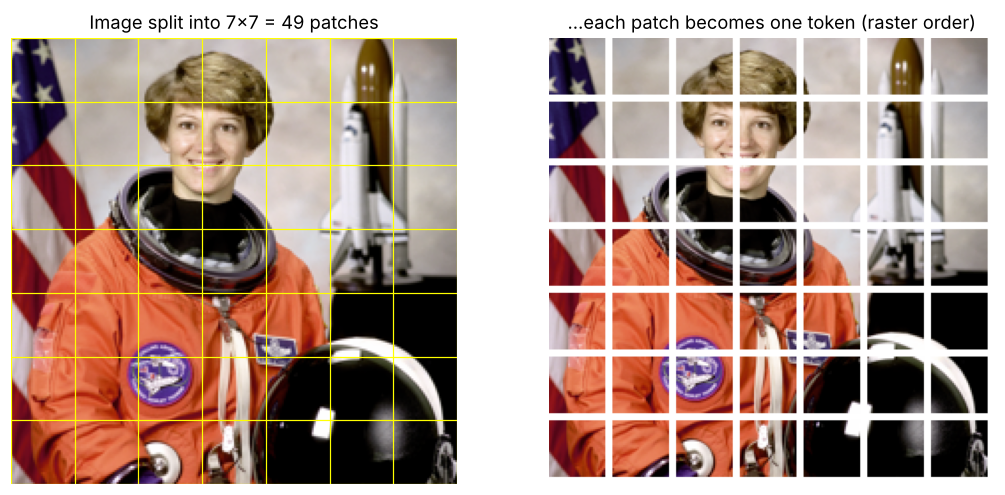

In [ ]:
P, D_EMB = 32, 768                                           # CLIP ViT-B/32: 32x32 patches, 768-d tokens
img = Image.fromarray(skdata.astronaut()).resize((224, 224))
x = torch.tensor(np.asarray(img), dtype=torch.float32).permute(2, 0, 1)[None] / 255.0   # [1, 3, 224, 224]

# (a) explicit: cut into patches, flatten, matrix multiply
patches = x.unfold(2, P, P).unfold(3, P, P)                  # [1, 3, 7, 7, 32, 32]
patches = patches.permute(0, 2, 3, 1, 4, 5).reshape(1, -1, 3 * P * P)   # [1, 49, 3072]: one row per patch
torch.manual_seed(SEED)
E = torch.randn(3 * P * P, D_EMB) * 0.02                     # a (random) patch-embedding matrix
tokens_explicit = patches @ E                                # [1, 49, 768]

# (b) as a strided convolution with the same weights
conv = nn.Conv2d(3, D_EMB, kernel_size=P, stride=P, bias=False)
with torch.no_grad():
    conv.weight.copy_(E.T.reshape(D_EMB, 3, P, P))           # reshape E into conv filters
    tokens_conv = conv(x).flatten(2).transpose(1, 2)         # [1, 49, 768]

print(f"Image 224×224, patch {P}×{P}  ->  N = (224/{P})² = {tokens_conv.shape[1]} visual tokens of dimension {D_EMB}")
print(f"max |explicit - conv| = {(tokens_explicit - tokens_conv).abs().max():.2e}")
assert torch.allclose(tokens_explicit, tokens_conv, atol=1e-4)
print("Verified: patch embedding == Conv2d(kernel=P, stride=P).")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), gridspec_kw={"width_ratios": [1, 1.1]})
axes[0].imshow(img)
for k in range(0, 225, P):
    axes[0].axhline(k - 0.5, color="yellow", lw=0.8); axes[0].axvline(k - 0.5, color="yellow", lw=0.8)
axes[0].set_title("Image split into 7×7 = 49 patches"); axes[0].axis("off")
grid = patches[0, :, :].reshape(49, 3, P, P)
mosaic = torch.ones(3, 7 * (P + 4), 7 * (P + 4))
for i in range(49):
    r, c = divmod(i, 7)
    mosaic[:, r * (P + 4):r * (P + 4) + P, c * (P + 4):c * (P + 4) + P] = grid[i]
axes[1].imshow(mosaic.permute(1, 2, 0).numpy()); axes[1].set_title("…each patch becomes one token (raster order)"); axes[1].axis("off")
save_fig("02a_patch_embedding")

### 2.2 The visual-token budget and token compression

The number of visual tokens is $N=(H/P)(W/P)$. It grows **quadratically with resolution**, and every token occupies a slot in the LLM's context. Higher resolution helps with text-rich images, but it costs tokens and time (Section 2.3). Production VLMs therefore compress visual tokens:
* **Pixel shuffle / space-to-depth** (Idefics3, SmolVLM): concatenate each $r\times r$ block of neighbouring tokens into one token with $r^2$ times more channels, so $N \to N/r^2$ without discarding information.
* **Patch merging** (Qwen2-VL merges 2×2 tokens), **learned queries** (BLIP-2's Q-Former, Flamingo's Perceiver resampler, Qwen-VL's 256-query cross-attention), and **hybrid conv-transformer encoders** that emit fewer tokens (FastVLM's FastViTHD).

In [ ]:
def n_tokens(res, patch, merge=1):
    # Visual tokens for a square image: (res/patch)^2, divided by merge^2 for token compression.
    return (res // patch) ** 2 // (merge ** 2)

budget = pd.DataFrame([
    ["CLIP ViT-B/32", 224, 32, 1, "none"],
    ["CLIP ViT-B/16", 224, 16, 1, "none"],
    ["LLaVA-1.5 (CLIP ViT-L/14-336)", 336, 14, 1, "none"],
    ["SmolVLM (SigLIP-B/16 @ 512)", 512, 16, 4, "pixel shuffle r=4"],
    ["Qwen2-VL @ 448×448", 448, 14, 2, "2×2 patch merge"],
    ["Gemma 3 (SigLIP @ 896)", 896, 14, 4, "pooling to 256 tokens"],
], columns=["Model / encoder", "Resolution", "Patch", "merge r", "Compression"])
budget["Patches (H/P)·(W/P)"] = [n_tokens(r, p) for r, p in zip(budget["Resolution"], budget["Patch"])]
budget["Tokens sent to the LLM"] = [n_tokens(r, p, m) for r, p, m in zip(budget["Resolution"], budget["Patch"], budget["merge r"])]
display(budget.drop(columns="merge r"))

,Model / encoder,Resolution,Patch,Compression,Patches (H/P)·(W/P),Tokens sent to the LLM
0,CLIP ViT-B/32,224,32,none,49,49
1,CLIP ViT-B/16,224,16,none,196,196
2,LLaVA-1.5 (CLIP ViT-L/14-336),336,14,none,576,576
3,SmolVLM (SigLIP-B/16 @ 512),512,16,pixel shuffle r=4,1024,64
4,Qwen2-VL @ 448×448,448,14,2×2 patch merge,1024,256
5,Gemma 3 (SigLIP @ 896),896,14,pooling to 256 tokens,4096,256


In [ ]:
def pixel_shuffle(tokens, r):
    # Space-to-depth on a square token grid: [B, N, D] -> [B, N/r^2, D*r^2].
    # Output token (i, j) is the concatenation of input tokens (r*i + a, r*j + b) for a, b in 0..r-1.
    B, N, D = tokens.shape
    s = int(math.isqrt(N))
    x = tokens.view(B, s // r, r, s // r, r, D)            # split rows and columns into blocks of r
    x = x.permute(0, 1, 3, 2, 4, 5)                         # [B, s/r, s/r, r, r, D]
    return x.reshape(B, (s // r) ** 2, r * r * D)

def pixel_unshuffle(tokens, r):
    # Exact inverse of pixel_shuffle.
    B, M, Dr = tokens.shape
    q, D = int(math.isqrt(M)), Dr // (r * r)
    x = tokens.view(B, q, q, r, r, D).permute(0, 1, 3, 2, 4, 5)
    return x.reshape(B, (q * r) ** 2, D)

feat = torch.randn(1, 32 * 32, 768)                          # SigLIP @ 512 px, patch 16 -> 32x32 = 1024 tokens
packed = pixel_shuffle(feat, 4)
print(f"before: {tuple(feat.shape)}  ->  after pixel shuffle (r=4): {tuple(packed.shape)}   ({feat.shape[1] // packed.shape[1]}× fewer tokens)")
assert torch.equal(pixel_unshuffle(packed, 4), feat)
print("Verified: pixel shuffle is lossless (the inverse recovers every value exactly).")

before: (1, 1024, 768)  ->  after pixel shuffle (r=4): (1, 64, 12288)   (16× fewer tokens)
Verified: pixel shuffle is lossless (the inverse recovers every value exactly).


### 2.3 Resolution vs latency (the FastVLM argument)

Apple's FastVLM work points out that **time-to-first-token (TTFT) = vision-encoding time + LLM pre-fill time**, and that both grow with resolution:
* self-attention over $N$ tokens costs $O(N^2)$;
* $N$ itself grows as $(\text{resolution})^2$.

We time a randomly initialised ViT encoder (6 layers, width 384, patch 16) at increasing resolutions and fit the empirical scaling exponent.

,resolution,visual tokens,encoder time (ms)
0,224,196,30.0
1,336,441,62.8
2,448,784,116.3
3,672,1764,566.7
4,896,3136,1462.0


Empirical scaling: time ∝ resolution^2.87  (≥ 2 expected: tokens grow as res², attention as tokens²)


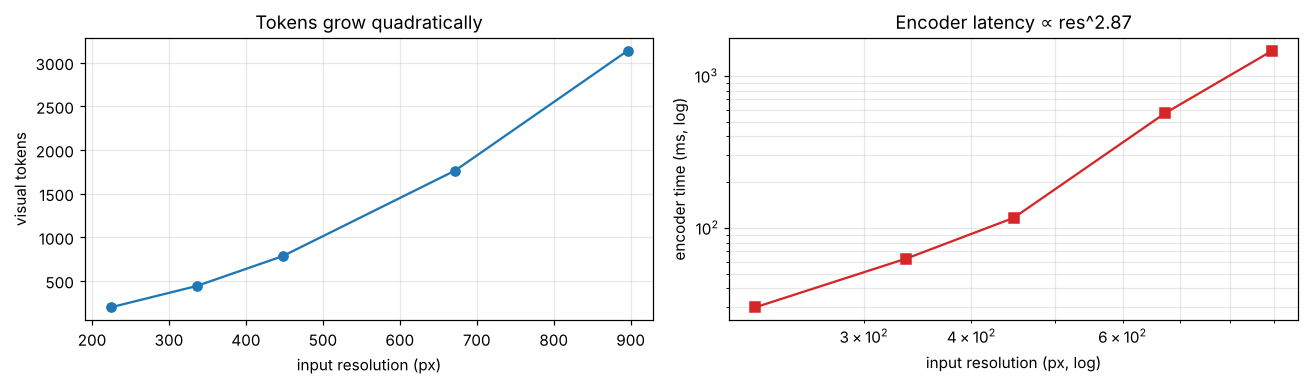

In [ ]:
class TinyViT(nn.Module):
    # A small ViT encoder used only to measure how cost scales with resolution.
    def __init__(self, patch=16, dim=384, depth=6, heads=6):
        super().__init__()
        self.embed = nn.Conv2d(3, dim, patch, patch)
        layer = nn.TransformerEncoderLayer(dim, heads, 4 * dim, dropout=0.0, batch_first=True, norm_first=True)
        self.blocks = nn.TransformerEncoder(layer, depth, enable_nested_tensor=False)
    def forward(self, x):
        return self.blocks(self.embed(x).flatten(2).transpose(1, 2))

vit = TinyViT().to(DEVICE).eval()
rows = []
with torch.no_grad():
    for res in [224, 336, 448, 672, 896]:
        xb = torch.randn(1, 3, res, res, device=DEVICE)
        for _ in range(2):
            vit(xb)                                                      # warm-up runs
        times = []
        for _ in range(5):
            if DEVICE.type == "cuda": torch.cuda.synchronize()
            t0 = time.perf_counter(); vit(xb)
            if DEVICE.type == "cuda": torch.cuda.synchronize()
            times.append(time.perf_counter() - t0)
        rows.append({"resolution": res, "visual tokens": n_tokens(res, 16), "encoder time (ms)": float(np.median(times)) * 1000})
df_lat = pd.DataFrame(rows)
slope = np.polyfit(np.log(df_lat["resolution"]), np.log(df_lat["encoder time (ms)"]), 1)[0]
display(df_lat.round(1))
print(f"Empirical scaling: time ∝ resolution^{slope:.2f}  (≥ 2 expected: tokens grow as res², attention as tokens²)")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(df_lat["resolution"], df_lat["visual tokens"], "o-"); ax[0].set_xlabel("input resolution (px)"); ax[0].set_ylabel("visual tokens"); ax[0].set_title("Tokens grow quadratically"); ax[0].grid(alpha=0.3)
ax[1].loglog(df_lat["resolution"], df_lat["encoder time (ms)"], "s-", color="C3"); ax[1].set_xlabel("input resolution (px, log)"); ax[1].set_ylabel("encoder time (ms, log)")
ax[1].set_title(f"Encoder latency ∝ res^{slope:.2f}"); ax[1].grid(alpha=0.3, which="both")
save_fig("02b_resolution_vs_latency")
del vit

## 3. Contrastive VLMs: building a mini-CLIP from scratch

### 3.1 The contrastive objective

Given a batch of $N$ image–text pairs with L2-normalised embeddings $u_i$ (image) and $v_j$ (text), CLIP (Radford et al., 2021) computes the similarity matrix $S_{ij} = \tau^{-1}\,u_i^\top v_j$, where the temperature $\tau$ is learned. It minimises the **symmetric InfoNCE** loss:
$$\mathcal L_{\text{CLIP}} = \frac{1}{2N}\sum_{i=1}^N\Big[-\log\frac{e^{S_{ii}}}{\sum_j e^{S_{ij}}} \;-\; \log\frac{e^{S_{ii}}}{\sum_j e^{S_{ji}}}\Big].$$
Each image must pick its own caption out of the $N$ captions in the batch, and vice versa.

**SigLIP** (Zhai et al., 2023) replaces the softmax with an independent binary decision for every pair:
$$\mathcal L_{\text{SigLIP}} = -\frac1N\sum_{i,j}\log\sigma\big(z_{ij}(t\,u_i^\top v_j + b)\big),\qquad z_{ij}=\begin{cases}+1 & i=j\\-1 & i\neq j\end{cases}.$$
Bordes et al. note that InfoNCE depends on the content of the mini-batch (hence CLIP's very large batches), whereas the sigmoid loss does not normalise across the batch.

We implement both losses and check three properties: agreement with an explicit loop, the value $\log N$ for uninformative embeddings, and the batch dependence.

In [ ]:
def clip_loss(img_emb, txt_emb, logit_scale):
    # Symmetric InfoNCE (CLIP). logit_scale = 1/temperature.
    u, v = F.normalize(img_emb, dim=-1), F.normalize(txt_emb, dim=-1)
    logits = logit_scale * u @ v.T                                    # S_ij
    target = torch.arange(len(u), device=u.device)                    # the i-th caption belongs to the i-th image
    return 0.5 * (F.cross_entropy(logits, target) + F.cross_entropy(logits.T, target))

def siglip_loss(img_emb, txt_emb, t=10.0, b=-10.0):
    # Pairwise sigmoid loss (SigLIP), averaged over images.
    u, v = F.normalize(img_emb, dim=-1), F.normalize(txt_emb, dim=-1)
    logits = t * u @ v.T + b
    z = 2 * torch.eye(len(u), device=u.device) - 1                    # +1 on the diagonal, -1 elsewhere
    return -F.logsigmoid(z * logits).sum() / len(u)

torch.manual_seed(SEED)
N, d = 8, 16
u, v = torch.randn(N, d), torch.randn(N, d)

# (1) explicit double loop vs vectorised implementation
S = 10.0 * F.normalize(u, dim=-1) @ F.normalize(v, dim=-1).T
loop = 0.0
for i in range(N):
    loop += -math.log(math.exp(S[i, i]) / sum(math.exp(S[i, j]) for j in range(N)))     # image -> text
    loop += -math.log(math.exp(S[i, i]) / sum(math.exp(S[j, i]) for j in range(N)))     # text -> image
loop /= 2 * N
print(f"(1) loop = {loop:.6f}   vectorised = {clip_loss(u, v, 10.0).item():.6f}")
assert abs(loop - clip_loss(u, v, 10.0).item()) < 1e-5

# (2) uninformative (all identical) embeddings -> every caption equally likely -> loss = log N
same = torch.ones(N, d)
print(f"(2) identical embeddings: loss = {clip_loss(same, same, 10.0).item():.4f}  vs  log N = {math.log(N):.4f}")
assert abs(clip_loss(same, same, 10.0).item() - math.log(N)) < 1e-5

# (3) batch dependence: the SAME pairs give a different InfoNCE when embedded in a larger batch
torch.manual_seed(1)
pairs_u, pairs_v = torch.randn(256, d), torch.randn(256, d)
pairs_v[:, :4] = pairs_u[:, :4] * 3                                    # make matching pairs moderately aligned
for n in [8, 32, 128, 256]:
    print(f"(3) batch size {n:3d}: InfoNCE = {clip_loss(pairs_u[:n], pairs_v[:n], 10.0).item():.3f}  "
          f"(log N = {math.log(n):.2f})   SigLIP per image = {siglip_loss(pairs_u[:n], pairs_v[:n]).item():.3f}")

(1) loop = 2.705580   vectorised = 2.705580
(2) identical embeddings: loss = 2.0794  vs  log N = 2.0794
(3) batch size   8: InfoNCE = 0.624  (log N = 2.08)   SigLIP per image = 6.047
(3) batch size  32: InfoNCE = 2.023  (log N = 3.47)   SigLIP per image = 5.890
(3) batch size 128: InfoNCE = 3.277  (log N = 4.85)   SigLIP per image = 5.861
(3) batch size 256: InfoNCE = 4.027  (log N = 5.55)   SigLIP per image = 6.032


### 3.2 A compositional scene dataset

To study what contrastive VLMs can and cannot learn, we generate a controlled dataset. Each $32\times64$ image contains **two objects**, one in each half, and its caption is **"a ⟨colour⟩ ⟨shape⟩ left of a ⟨colour⟩ ⟨shape⟩"**. There are 6 colours × 4 shapes = 24 objects and 552 ordered object pairs. Position, size and brightness jitter plus pixel noise make every rendering different.

**20% of the object pairs (110 combinations) are held out entirely.** Their captions and images never appear during training, so they test **compositional zero-shot generalisation**: recognising new combinations of known concepts (cf. the "yellow horse" example in the Encord guide).

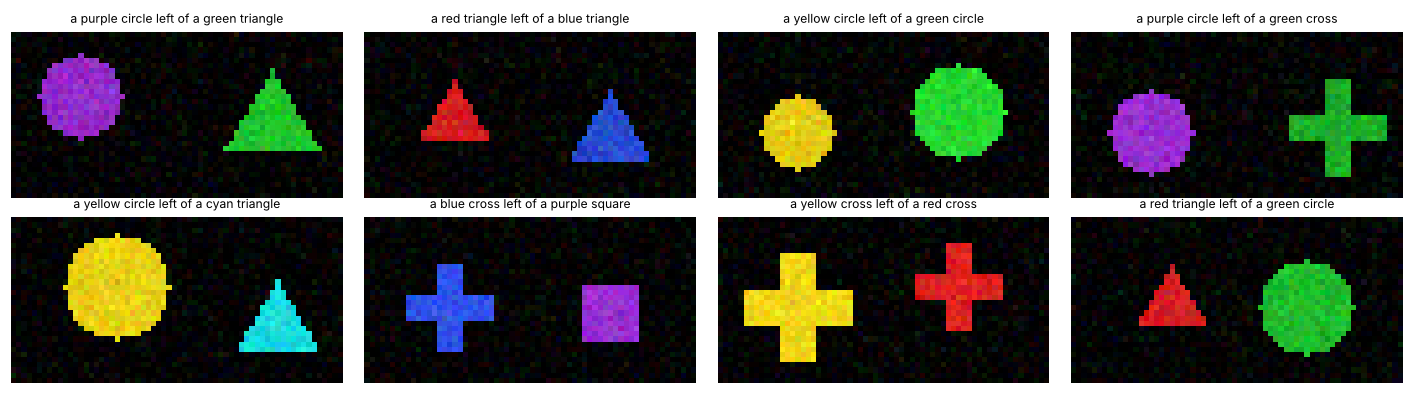

24 objects, 552 ordered pairs: 442 for training, 110 held out. Vocabulary: 24 words.


In [ ]:
COLOURS = {"red": (1.0, 0.15, 0.15), "green": (0.15, 0.85, 0.2), "blue": (0.2, 0.35, 1.0),
           "yellow": (1.0, 0.9, 0.1), "purple": (0.65, 0.2, 0.9), "cyan": (0.1, 0.9, 0.9)}
SHAPES = ["circle", "square", "triangle", "cross"]
OBJECTS = [(c, s) for c in COLOURS for s in SHAPES]                       # 24 objects
PAIRS = [(a, b) for a in range(len(OBJECTS)) for b in range(len(OBJECTS)) if a != b]   # 552 ordered pairs
perm = torch.randperm(len(PAIRS), generator=torch.Generator().manual_seed(SEED)).tolist()
n_hold = int(0.2 * len(PAIRS))
HELDOUT_PAIRS = [PAIRS[i] for i in perm[:n_hold]]                         # never seen in training
TRAIN_PAIRS = [PAIRS[i] for i in perm[n_hold:]]

_yy, _xx = torch.meshgrid(torch.arange(32.0), torch.arange(32.0), indexing="ij")

def shape_mask(shape, cx, cy, r):
    # Boolean 32x32 mask of a shape centred at (cx, cy) with radius r.
    dx, dy = _xx - cx, _yy - cy
    if shape == "circle":   return dx ** 2 + dy ** 2 <= r * r
    if shape == "square":   return (dx.abs() <= 0.85 * r) & (dy.abs() <= 0.85 * r)
    if shape == "triangle": return (dy <= 0.8 * r) & (dy >= -0.9 * r) & (dx.abs() <= (dy + 0.9 * r) * 0.6)
    return ((dx.abs() <= 0.3 * r) & (dy.abs() <= r)) | ((dy.abs() <= 0.3 * r) & (dx.abs() <= r))   # cross

def render(pair, g):
    # Render the two objects of an ordered pair into a 3x32x64 image (left object in the left half).
    img = torch.zeros(3, 32, 64)
    for k, obj_idx in enumerate(pair):
        colour, shape = OBJECTS[obj_idx]
        cx, cy = 16 + torch.randint(-4, 5, (2,), generator=g)              # position jitter
        r = 7 + torch.randint(0, 4, (1,), generator=g).item()               # size jitter
        rgb = torch.tensor(COLOURS[colour]) * (0.8 + 0.2 * torch.rand(1, generator=g))   # brightness jitter
        img[:, :, 32 * k:32 * k + 32][:, shape_mask(shape, cx.item(), cy.item(), r)] = rgb[:, None]
    return (img + 0.05 * torch.randn(img.shape, generator=g)).clamp(0, 1)

def caption(pair):
    (c1, s1), (c2, s2) = OBJECTS[pair[0]], OBJECTS[pair[1]]
    return f"a {c1} {s1} left of a {c2} {s2}"

VOCAB = ["<pad>", "<bos>", "<eos>", "a", "left", "of", *COLOURS, *SHAPES,
         "describe", "what", "colour", "shape", "is", "the", "right", "object"]
STOI = {w: i for i, w in enumerate(VOCAB)}
def tokenize(text):
    return [STOI[w] for w in text.split()]

def sample_batch(pairs, n, g):
    # n random scenes from a list of pairs -> (images [n,3,32,64], list of pairs)
    idx = torch.randint(0, len(pairs), (n,), generator=g).tolist()
    chosen = [pairs[i] for i in idx]
    return torch.stack([render(p, g) for p in chosen]), chosen

def caption_tokens(pairs):
    return torch.tensor([tokenize(caption(p)) for p in pairs])             # every caption has 9 tokens

g_demo = torch.Generator().manual_seed(0)
demo_imgs, demo_pairs = sample_batch(TRAIN_PAIRS, 8, g_demo)
fig, axes = plt.subplots(2, 4, figsize=(13, 3.6))
for ax, im, p in zip(axes.ravel(), demo_imgs, demo_pairs):
    ax.imshow(im.permute(1, 2, 0)); ax.set_title(caption(p), fontsize=8); ax.axis("off")
save_fig("03a_scene_dataset")
print(f"{len(OBJECTS)} objects, {len(PAIRS)} ordered pairs: {len(TRAIN_PAIRS)} for training, {len(HELDOUT_PAIRS)} held out. Vocabulary: {len(VOCAB)} words.")

### 3.3 Two mini-CLIPs: bag-of-words vs transformer text encoder

Both models share the same **image encoder**: a small CNN producing a $4\times8$ grid of 32 visual tokens, followed by one self-attention layer, mean-pooling and a projection. They differ only in the **text encoder**:
* **Bag-of-words (BoW):** average of word embeddings, then an MLP. It ignores word order by construction.
* **Transformer:** word embeddings plus *positional* embeddings, two self-attention layers, mean-pooling and a projection.

Both are trained with the CLIP loss of Section 3.1 (learnable temperature), the same number of steps and the same data.

*Implementation note:* the positional embeddings are initialised with a clearly non-zero scale (std 0.3). With a near-zero initialisation, both encoders start out position-blind and take much longer to discover word order and left/right position. Breaking this symmetry from the start makes training reliable within the step budget.

[BoW] step 200/800 | CLIP loss 1.714 |  46.8s


[BoW] step 400/800 | CLIP loss 0.931 |  93.6s


[BoW] step 600/800 | CLIP loss 0.892 | 141.6s


[BoW] step 800/800 | CLIP loss 0.880 | 188.9s


[Transformer] step 200/800 | CLIP loss 1.797 |  50.5s


[Transformer] step 400/800 | CLIP loss 0.530 |  99.8s


[Transformer] step 600/800 | CLIP loss 0.418 | 149.0s


[Transformer] step 800/800 | CLIP loss 0.413 | 199.1s


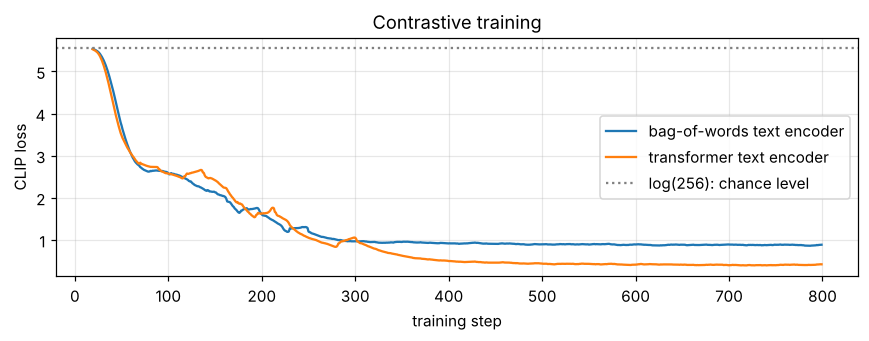

In [ ]:
class ImageEncoder(nn.Module):
    # CNN -> 4x8 grid of visual tokens -> self-attention -> pooled embedding.
    def __init__(self, d=64):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),     # 32x64 -> 16x32
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # -> 8x16
            nn.Conv2d(32, d, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))     # -> 4x8 = 32 tokens
        self.pos = nn.Parameter(torch.randn(1, 32, d) * 0.3)    # position of each visual token (left vs right half)
        self.attn = nn.TransformerEncoder(nn.TransformerEncoderLayer(d, 4, 2 * d, 0.0, batch_first=True), 1,
                                          enable_nested_tensor=False)
        self.proj = nn.Linear(d, d)
    def tokens(self, x):                                   # visual tokens (used later by the mini-LLaVA)
        return self.attn(self.cnn(x).flatten(2).transpose(1, 2) + self.pos)
    def forward(self, x):                                  # pooled image embedding for contrastive learning
        return self.proj(self.tokens(x).mean(1))

class BagOfWordsEncoder(nn.Module):
    # Order-insensitive text encoder: mean of word embeddings.
    def __init__(self, d=64):
        super().__init__()
        self.emb = nn.Embedding(len(VOCAB), d)
        self.mlp = nn.Sequential(nn.Linear(d, d), nn.ReLU(), nn.Linear(d, d))
    def forward(self, t):
        return self.mlp(self.emb(t).mean(1))

class TransformerTextEncoder(nn.Module):
    # Order-aware text encoder: embeddings + positions + self-attention.
    def __init__(self, d=64, max_len=12):
        super().__init__()
        self.emb = nn.Embedding(len(VOCAB), d)
        self.pos = nn.Parameter(torch.randn(1, max_len, d) * 0.3)   # word positions (a near-zero init learns order slowly)
        self.enc = nn.TransformerEncoder(nn.TransformerEncoderLayer(d, 4, 2 * d, 0.0, batch_first=True), 2,
                                         enable_nested_tensor=False)
        self.proj = nn.Linear(d, d)
    def forward(self, t):
        return self.proj(self.enc(self.emb(t) + self.pos[:, :t.size(1)]).mean(1))

def train_mini_clip(text_encoder_cls, steps=MINI_CLIP_STEPS, batch=256, name=""):
    # Train image + text encoders with the CLIP loss on the training pairs.
    set_seed()
    img_enc, txt_enc = ImageEncoder().to(DEVICE), text_encoder_cls().to(DEVICE)
    log_scale = nn.Parameter(torch.tensor(math.log(10.0), device=DEVICE))      # learnable 1/temperature
    params = list(img_enc.parameters()) + list(txt_enc.parameters()) + [log_scale]
    opt = torch.optim.Adam(params, lr=2e-3)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=2e-3, total_steps=steps, pct_start=0.1)
    g = torch.Generator().manual_seed(1)
    losses, t0 = [], time.time()
    for step in range(steps):
        x, pairs = sample_batch(TRAIN_PAIRS, batch, g)
        loss = clip_loss(img_enc(x.to(DEVICE)), txt_enc(caption_tokens(pairs).to(DEVICE)), log_scale.exp().clamp(max=100))
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        losses.append(loss.item())
        if (step + 1) % 200 == 0:
            print(f"[{name}] step {step + 1}/{steps} | CLIP loss {np.mean(losses[-50:]):.3f} | {time.time() - t0:5.1f}s")
    return img_enc.eval(), txt_enc.eval(), losses

bow_img, bow_txt, bow_losses = train_mini_clip(BagOfWordsEncoder, name="BoW")
tf_img, tf_txt, tf_losses = train_mini_clip(TransformerTextEncoder, name="Transformer")

plt.figure(figsize=(8, 3.2))
plt.plot(pd.Series(bow_losses).rolling(20).mean(), label="bag-of-words text encoder")
plt.plot(pd.Series(tf_losses).rolling(20).mean(), label="transformer text encoder")
plt.axhline(math.log(256), color="gray", ls=":", label="log(256): chance level")
plt.xlabel("training step"); plt.ylabel("CLIP loss"); plt.legend(); plt.grid(alpha=0.3); plt.title("Contrastive training")
save_fig("03b_mini_clip_training")

### 3.4 Evaluation: zero-shot retrieval and an ARO-style compositionality test

* **Zero-shot retrieval:** for each test image, rank **all 552 captions** and check whether the correct one is ranked first. On held-out pairs the model has never seen the image or the caption.
* **Order test (ARO, Yuksekgonul et al., 2023):** does the model prefer the true caption over the caption with the objects swapped ("a blue square left of a red circle")?
* **Attribute-binding test:** does it prefer the true caption over one with the **colours exchanged** between the two objects ("a blue circle left of a red square")?

Both distractors contain **exactly the same words** as the true caption, so a model that treats text as a bag of words *cannot* do better than chance (50%).

In [ ]:
@torch.no_grad()
def evaluate_mini_clip(img_enc, txt_enc, pairs, n=600, seed=5):
    g = torch.Generator().manual_seed(seed)
    x, chosen = sample_batch(pairs, n, g)
    U = F.normalize(img_enc(x.to(DEVICE)), dim=-1)
    all_T = F.normalize(txt_enc(caption_tokens(PAIRS).to(DEVICE)), dim=-1)
    truth = torch.tensor([PAIRS.index(p) for p in chosen], device=DEVICE)
    retrieval = ((U @ all_T.T).argmax(1) == truth).float().mean().item() * 100

    def preference(alt_pairs):
        # % of images whose true caption scores higher than the alternative (ties count as 1/2)
        s_true = (U * F.normalize(txt_enc(caption_tokens(chosen).to(DEVICE)), dim=-1)).sum(1)
        s_alt = (U * F.normalize(txt_enc(caption_tokens(alt_pairs).to(DEVICE)), dim=-1)).sum(1)
        tie = (s_true - s_alt).abs() < 1e-5
        return (((s_true > s_alt) & ~tie).float() + 0.5 * tie.float()).mean().item() * 100

    order = preference([(b, a) for a, b in chosen])
    keep = [i for i, (a, b) in enumerate(chosen) if OBJECTS[a][0] != OBJECTS[b][0]]   # colours must differ
    swapped = [(OBJECTS.index((OBJECTS[b][0], OBJECTS[a][1])), OBJECTS.index((OBJECTS[a][0], OBJECTS[b][1])))
               for a, b in chosen]
    U_keep = U[keep]; chosen_keep = [chosen[i] for i in keep]; swapped_keep = [swapped[i] for i in keep]
    s_true = (U_keep * F.normalize(txt_enc(caption_tokens(chosen_keep).to(DEVICE)), dim=-1)).sum(1)
    s_alt = (U_keep * F.normalize(txt_enc(caption_tokens(swapped_keep).to(DEVICE)), dim=-1)).sum(1)
    tie = (s_true - s_alt).abs() < 1e-5
    binding = (((s_true > s_alt) & ~tie).float() + 0.5 * tie.float()).mean().item() * 100
    return {"retrieval top-1 % (552 captions)": retrieval, "order test %": order, "attribute-binding test %": binding}

rows = {}
for name, (ie, te) in {"BoW text encoder": (bow_img, bow_txt), "Transformer text encoder": (tf_img, tf_txt)}.items():
    for split, pairs in [("seen pairs", TRAIN_PAIRS), ("held-out pairs", HELDOUT_PAIRS)]:
        rows[(name, split)] = evaluate_mini_clip(ie, te, pairs)
df_clip_eval = pd.DataFrame(rows).T
display(df_clip_eval.round(1))
print(f"Chance levels: retrieval {100 / len(PAIRS):.2f}%, order and binding tests 50%.")

retrieval top-1 % (552 captions)  \
BoW text encoder         seen pairs                                  30.5   
                         held-out pairs                              34.3   
Transformer text encoder seen pairs                                  99.8   
                         held-out pairs                              98.5   

                                         order test %  \
BoW text encoder         seen pairs              50.0   
                         held-out pairs          50.0   
Transformer text encoder seen pairs             100.0   
                         held-out pairs         100.0   

                                         attribute-binding test %  
BoW text encoder         seen pairs                          50.0  
                         held-out pairs                      50.0  
Transformer text encoder seen pairs                         100.0  
                         held-out pairs                     100.0

Chance levels: retrieval 0.18%, order and binding tests 50%.


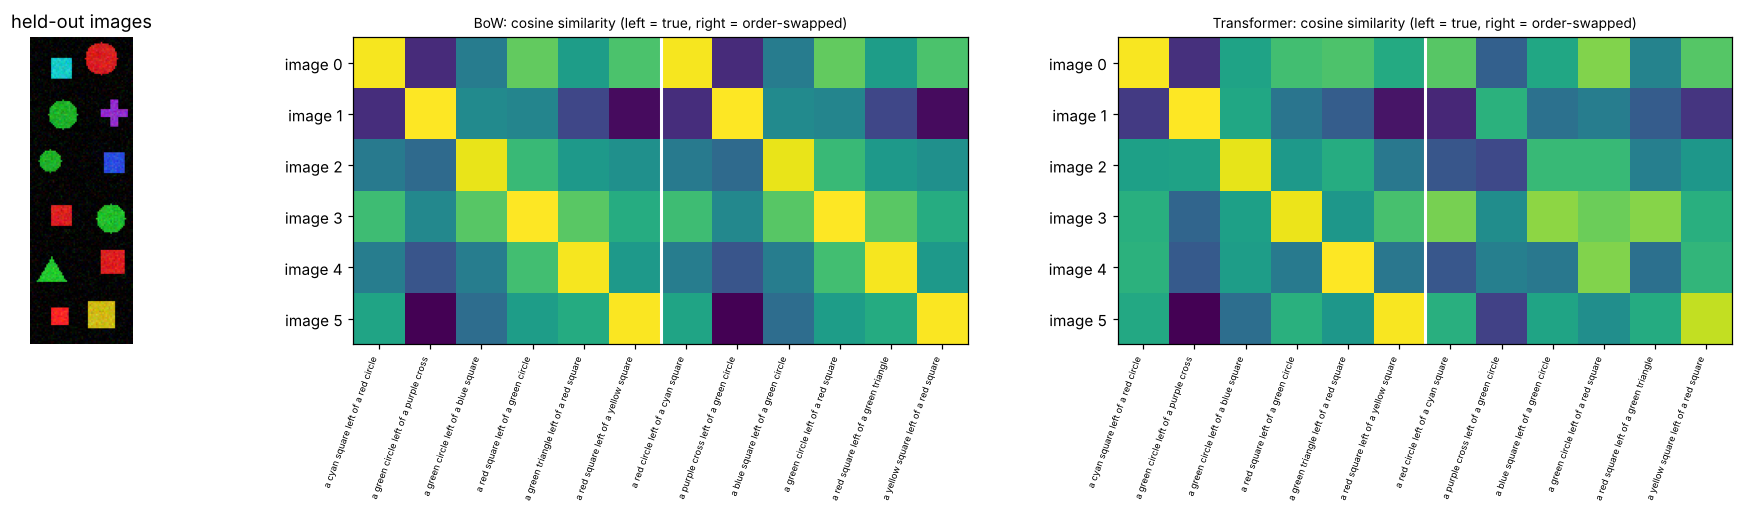

In [ ]:
# Similarity matrix for 6 held-out images vs their captions and their "order-swapped" captions
g = torch.Generator().manual_seed(9)
x6, p6 = sample_batch(HELDOUT_PAIRS, 6, g)
cands = [caption(p) for p in p6] + [caption((b, a)) for a, b in p6]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.3), gridspec_kw={"width_ratios": [1, 2.2, 2.2]})
axes[0].imshow(torch.cat(list(x6), dim=1).permute(1, 2, 0)); axes[0].set_title("held-out images"); axes[0].axis("off")
with torch.no_grad():
    for ax, (name, ie, te) in zip(axes[1:], [("BoW", bow_img, bow_txt), ("Transformer", tf_img, tf_txt)]):
        sim = (F.normalize(ie(x6.to(DEVICE)), dim=-1) @ F.normalize(te(torch.tensor([tokenize(c) for c in cands]).to(DEVICE)), dim=-1).T).cpu()
        ax.imshow(sim, cmap="viridis"); ax.set_yticks(range(6)); ax.set_yticklabels([f"image {i}" for i in range(6)])
        ax.set_xticks(range(12)); ax.set_xticklabels(cands, rotation=70, ha="right", fontsize=6)
        ax.axvline(5.5, color="white", lw=2); ax.set_title(f"{name}: cosine similarity (left = true, right = order-swapped)", fontsize=9)
save_fig("03c_similarity_matrices")

**Findings.**
* **The BoW model hits a ceiling.** It recognises *which* colours and shapes are present, but it scores the true caption and its word-permuted twin identically. It is therefore stuck at ≈50% on the order and binding tests, and it cannot reliably retrieve the exact caption. Its loss also plateaus well above zero, because pairs differing only in word order are indistinguishable to it.
* **Word order matters.** With positional information and self-attention, the transformer text encoder solves the order test and most of the binding test. It also **generalises to object combinations it never saw**: held-out accuracy is close to seen-pair accuracy.

This is exactly the "VLMs can behave like bags of words" issue raised by ARO and the Encord guide, here isolated in a controlled setting. Real CLIP models are known to show it partially, which is why benchmarks such as Winoground, ARO and SugarCrepe exist.

## 4. Generative VLMs: building a mini-LLaVA from scratch

We now build a **generative** VLM with the LLaVA architecture of Section 1.3:
* **Vision encoder:** the image encoder of the transformer mini-CLIP from Section 3, **frozen**, giving 32 visual tokens of dimension 64.
* **Projector:** a 2-layer MLP mapping each visual token to the decoder's width (128).
* **Language decoder:** a 2-layer causal transformer over the sequence `[32 visual tokens] [question tokens] [<bos> answer tokens <eos>]`, trained with next-token cross-entropy on the **answer tokens only**.

The **instruction data** covers five instructions per image: *describe*, *what colour is the left/right object*, *what shape is the left/right object*.

Training follows the LLaVA recipe, and we measure accuracy (exact match of the generated answer) on **held-out object pairs** after each stage:
* **Stage 0 — "pre-trained LLM":** train the decoder on question → answer text **without images**. It can only learn the language prior.
* **Stage 1 — alignment:** freeze the decoder, train **only the projector**.
* **Stage 2 — instruction tuning:** train projector and decoder together.

In [ ]:
INSTRUCTIONS = [("describe",                        lambda p: caption(p)),
                ("what colour is the left object",  lambda p: OBJECTS[p[0]][0]),
                ("what colour is the right object", lambda p: OBJECTS[p[1]][0]),
                ("what shape is the left object",   lambda p: OBJECTS[p[0]][1]),
                ("what shape is the right object",  lambda p: OBJECTS[p[1]][1])]
MAX_Q, MAX_A, N_VIS = 6, 11, 32                       # question length, answer length (incl. <bos>/<eos>), visual tokens

def instruction_batch(pairs, g):
    # Random instruction per scene -> padded question / answer token tensors and the instruction ids.
    kinds = torch.randint(0, len(INSTRUCTIONS), (len(pairs),), generator=g)
    Q = torch.zeros(len(pairs), MAX_Q, dtype=torch.long); A = torch.zeros(len(pairs), MAX_A, dtype=torch.long)
    for i, (p, k) in enumerate(zip(pairs, kinds.tolist())):
        q = tokenize(INSTRUCTIONS[k][0]); a = [STOI["<bos>"]] + tokenize(INSTRUCTIONS[k][1](p)) + [STOI["<eos>"]]
        Q[i, :len(q)] = torch.tensor(q); A[i, :len(a)] = torch.tensor(a)
    return Q, A, kinds

class MiniLLaVA(nn.Module):
    def __init__(self, d_vis=64, d=128, layers=2):
        super().__init__()
        self.projector = nn.Sequential(nn.Linear(d_vis, d), nn.GELU(), nn.Linear(d, d))     # vision -> LLM space
        self.embed = nn.Embedding(len(VOCAB), d)
        self.pos = nn.Parameter(torch.randn(1, N_VIS + MAX_Q + MAX_A, d) * 0.02)
        layer = nn.TransformerEncoderLayer(d, 4, 2 * d, 0.0, batch_first=True, norm_first=True)
        self.decoder = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)       # used with a causal mask
        self.lm_head = nn.Linear(d, len(VOCAB))

    def forward(self, vis_tokens, Q, A, use_image=True):
        B = Q.size(0)
        v = self.projector(vis_tokens) if use_image else torch.zeros(B, N_VIS, self.embed.embedding_dim, device=Q.device)
        x = torch.cat([v, self.embed(Q), self.embed(A)], dim=1) + self.pos
        n = x.size(1)
        causal = torch.triu(torch.full((n, n), float("-inf"), device=Q.device), diagonal=1)     # no peeking ahead
        h = self.decoder(x, mask=causal)
        return self.lm_head(h[:, N_VIS + MAX_Q - 1:-1])     # position t predicts answer token t (teacher forcing)

def answer_loss(model, vis, Q, A, use_image=True):
    logits = model(vis, Q, A, use_image)                    # [B, MAX_A, V]; logits[:, j] predicts A[:, j]
    return F.cross_entropy(logits[:, 1:].reshape(-1, logits.size(-1)), A[:, 1:].reshape(-1), ignore_index=0)

@torch.no_grad()
def generate_answers(model, vis, Q, use_image=True):
    # Greedy autoregressive decoding of the answer.
    A = torch.zeros(Q.size(0), MAX_A, dtype=torch.long, device=Q.device); A[:, 0] = STOI["<bos>"]
    for j in range(1, MAX_A):
        A[:, j] = model(vis, Q, A, use_image)[:, j].argmax(-1)
    return A

def detok(seq):
    words = []
    for t in seq.tolist()[1:]:
        if t in (STOI["<pad>"], STOI["<eos>"]): break
        words.append(VOCAB[t])
    return " ".join(words)

vision_encoder = tf_img                                    # frozen vision encoder from Section 3
for p_ in vision_encoder.parameters(): p_.requires_grad_(False)

@torch.no_grad()
def evaluate_llava(model, pairs, use_image=True, n=600, seed=7):
    model.eval()
    g = torch.Generator().manual_seed(seed)
    x, chosen = sample_batch(pairs, n, g)
    Q, A, kinds = instruction_batch(chosen, g)
    Q, A = Q.to(DEVICE), A.to(DEVICE)
    pred = generate_answers(model, vision_encoder.tokens(x.to(DEVICE)), Q, use_image)
    correct = torch.tensor([detok(p) == detok(a) for p, a in zip(pred, A)]).float()
    model.train()
    out = {"overall %": correct.mean().item() * 100}
    for k, (q, _) in enumerate(INSTRUCTIONS):
        out[q] = correct[kinds == k].mean().item() * 100
    return out

def run_stage(model, params, use_image, steps=MINI_LLAVA_STEPS, name=""):
    opt = torch.optim.Adam(params, lr=1e-3)
    g = torch.Generator().manual_seed(11)
    t0 = time.time()
    for step in range(steps):
        x, chosen = sample_batch(TRAIN_PAIRS, 128, g)
        Q, A, _ = instruction_batch(chosen, g)
        with torch.no_grad():
            vis = vision_encoder.tokens(x.to(DEVICE))        # frozen encoder
        loss = answer_loss(model, vis, Q.to(DEVICE), A.to(DEVICE), use_image)
        opt.zero_grad(); loss.backward(); opt.step()
    print(f"[{name}] {steps} steps | final loss {loss.item():.3f} | {time.time() - t0:5.1f}s")

set_seed()
llava = MiniLLaVA().to(DEVICE)
decoder_params = list(llava.embed.parameters()) + [llava.pos] + list(llava.decoder.parameters()) + list(llava.lm_head.parameters())
stage_results = {}

run_stage(llava, decoder_params, use_image=False, name="Stage 0: text-only LM")
stage_results["Stage 0: LM only (no image)"] = evaluate_llava(llava, HELDOUT_PAIRS, use_image=False)
run_stage(llava, list(llava.projector.parameters()), use_image=True, name="Stage 1: projector only")
stage_results["Stage 1: + projector alignment"] = evaluate_llava(llava, HELDOUT_PAIRS)
run_stage(llava, list(llava.parameters()), use_image=True, name="Stage 2: projector + decoder")
stage_results["Stage 2: + instruction tuning"] = evaluate_llava(llava, HELDOUT_PAIRS)
stage_results["Stage 2 model, image removed"] = evaluate_llava(llava, HELDOUT_PAIRS, use_image=False)

df_stages = pd.DataFrame(stage_results).T
display(df_stages.round(1))
print("Chance for colour questions = 16.7%, shape questions = 25%, exact caption = 1/552.")

[Stage 0: text-only LM] 400 steps | final loss 0.765 |  67.8s


[Stage 1: projector only] 400 steps | final loss 0.530 |  70.1s


[Stage 2: projector + decoder] 400 steps | final loss 0.002 |  69.6s


,overall %,describe,what colour is the left object,what colour is the right object,what shape is the left object,what shape is the right object
Stage 0: LM only (no image),17.8,0.0,10.6,14.4,31.6,32.0
Stage 1: + projector alignment,47.3,2.5,64.4,46.2,86.3,36.7
Stage 2: + instruction tuning,99.7,99.2,100.0,100.0,100.0,99.2
"Stage 2 model, image removed",13.0,0.0,10.6,15.4,19.7,19.5


Chance for colour questions = 16.7%, shape questions = 25%, exact caption = 1/552.


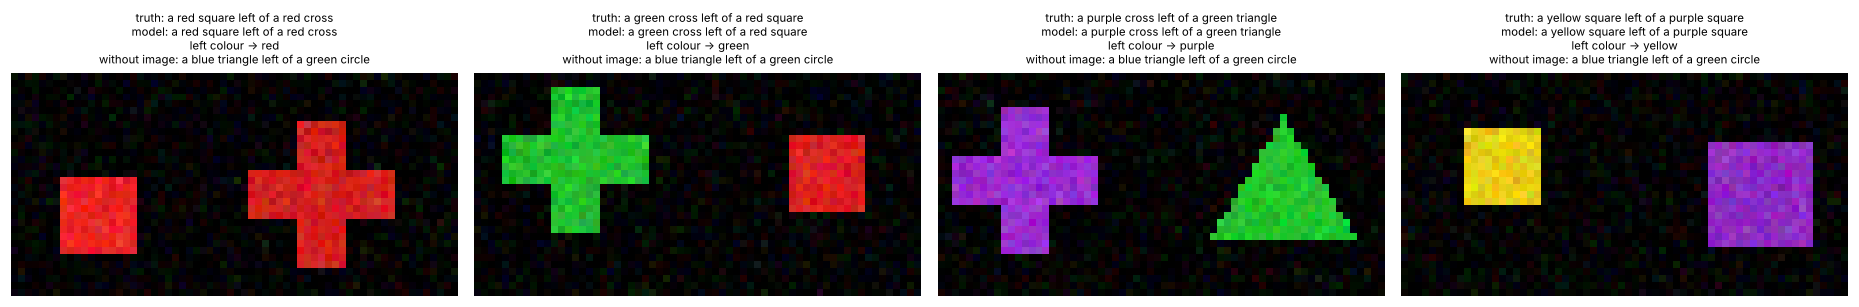

In [ ]:
# What does each model say about the same held-out images?
g = torch.Generator().manual_seed(21)
xs, ps = sample_batch(HELDOUT_PAIRS, 4, g)
Qd = torch.tensor([tokenize("describe") + [0] * (MAX_Q - 1)] * 4, device=DEVICE)
Qc = torch.tensor([tokenize("what colour is the left object") + [0] * (MAX_Q - 6)] * 4, device=DEVICE)
llava.eval()
with torch.no_grad():
    vis = vision_encoder.tokens(xs.to(DEVICE))
    cap_img = [detok(a) for a in generate_answers(llava, vis, Qd)]
    cap_blind = [detok(a) for a in generate_answers(llava, vis, Qd, use_image=False)]
    col_img = [detok(a) for a in generate_answers(llava, vis, Qc)]
fig, axes = plt.subplots(1, 4, figsize=(17, 3.3))
for i, ax in enumerate(axes):
    ax.imshow(xs[i].permute(1, 2, 0)); ax.axis("off")
    ax.set_title(f"truth: {caption(ps[i])}\nmodel: {cap_img[i]}\nleft colour → {col_img[i]}\nwithout image: {cap_blind[i]}", fontsize=7.5)
save_fig("04_mini_llava_outputs")

**Findings.**
* **Stage 0 (no image)** answers fluently and in the right format, but at chance accuracy: it has only learned *what answers look like*. This is the language prior that causes **hallucination** in real VLMs, which can produce confident, well-formed answers that are not grounded in the image.
* **Stage 1** (only the small projector is trained) already connects vision to the frozen decoder, so accuracy rises well above chance. This is why LLaVA's cheap alignment stage works.
* **Stage 2** (instruction tuning of projector and decoder) reaches high accuracy on **object combinations never seen in training**, including complete captions.
* **Removing the image** from the final model drops it back to chance, which confirms its answers are genuinely grounded in the visual tokens.

## 5. Real pretrained VLMs

### 5.1 CLIP: a contrastive two-tower model

`openai/clip-vit-base-patch32` was trained with the loss of Section 3.1 on 400M web image–text pairs. It has a ViT-B/32 image tower (49 patch tokens + 1 class token at 224 px) and a 12-layer text transformer, both projected to a shared 512-d space.

To be robust across transformers versions, we compute embeddings by calling the two towers and their projection layers directly. We then verify that this reproduces the model's own `logits_per_image` and its built-in contrastive loss.

In [ ]:
clip_model = CLIPModel.from_pretrained(CLIP_ID, dtype=torch.float32).to(DEVICE).eval()
clip_proc = CLIPProcessor.from_pretrained(CLIP_ID)

def count(m):
    return sum(p.numel() for p in m.parameters())
print(f"CLIP parameters: vision tower {count(clip_model.vision_model) / 1e6:.1f}M | text tower {count(clip_model.text_model) / 1e6:.1f}M | "
      f"total {count(clip_model) / 1e6:.1f}M | learned temperature 1/τ = {clip_model.logit_scale.exp().item():.1f}")

@torch.no_grad()
def clip_image_embed(images, batch=64):
    # L2-normalised CLIP image embeddings for a list of PIL images.
    out = []
    for i in range(0, len(images), batch):
        pv = clip_proc(images=images[i:i + batch], return_tensors="pt")["pixel_values"].to(DEVICE)
        pooled = clip_model.vision_model(pixel_values=pv).pooler_output        # class-token representation
        out.append(F.normalize(clip_model.visual_projection(pooled), dim=-1).cpu())
    return torch.cat(out)

@torch.no_grad()
def clip_text_embed(texts, batch=256):
    # L2-normalised CLIP text embeddings for a list of strings (truncated to CLIP's 77-token limit).
    out = []
    for i in range(0, len(texts), batch):
        tok = clip_proc(text=texts[i:i + batch], return_tensors="pt", padding=True, truncation=True, max_length=77)
        pooled = clip_model.text_model(input_ids=tok["input_ids"].to(DEVICE), attention_mask=tok["attention_mask"].to(DEVICE)).pooler_output
        out.append(F.normalize(clip_model.text_projection(pooled), dim=-1).cpu())
    return torch.cat(out)

SAMPLES = {"astronaut": skdata.astronaut(), "cat": skdata.chelsea(), "coffee": skdata.coffee(),
           "rocket": skdata.rocket(), "retina": skdata.retina(), "motorcycle": skdata.stereo_motorcycle()[0]}
sample_images = {k: Image.fromarray(v).convert("RGB") for k, v in SAMPLES.items()}
LABELS = ["an astronaut", "a cat", "a cup of coffee", "a rocket launch", "a retinal fundus photograph",
          "a motorcycle", "a dog", "a car", "a pizza", "a chest X-ray"]

# Verification against the model's own forward pass and built-in loss
imgs = list(sample_images.values()); texts = [f"a photo of {l}" for l in LABELS[:6]]
with torch.no_grad():
    inputs = clip_proc(text=texts, images=imgs, return_tensors="pt", padding=True).to(DEVICE)
    out = clip_model(**inputs, return_loss=True)
ours = clip_model.logit_scale.exp().item() * clip_image_embed(imgs) @ clip_text_embed(texts).T
print(f"max |our logits - model.logits_per_image| = {(ours - out.logits_per_image.cpu()).abs().max():.2e}")
print(f"built-in CLIP loss = {out.loss.item():.5f}   our clip_loss() = {clip_loss(clip_image_embed(imgs), clip_text_embed(texts), clip_model.logit_scale.exp().item()).item():.5f}")
assert torch.allclose(ours, out.logits_per_image.cpu(), atol=1e-3)
assert abs(out.loss.item() - clip_loss(clip_image_embed(imgs), clip_text_embed(texts), clip_model.logit_scale.exp().item()).item()) < 1e-3

CLIP parameters: vision tower 87.5M | text tower 63.2M | total 151.3M | learned temperature 1/τ = 100.0


max |our logits - model.logits_per_image| = 7.63e-06


built-in CLIP loss = 0.00406   our clip_loss() = 0.00406


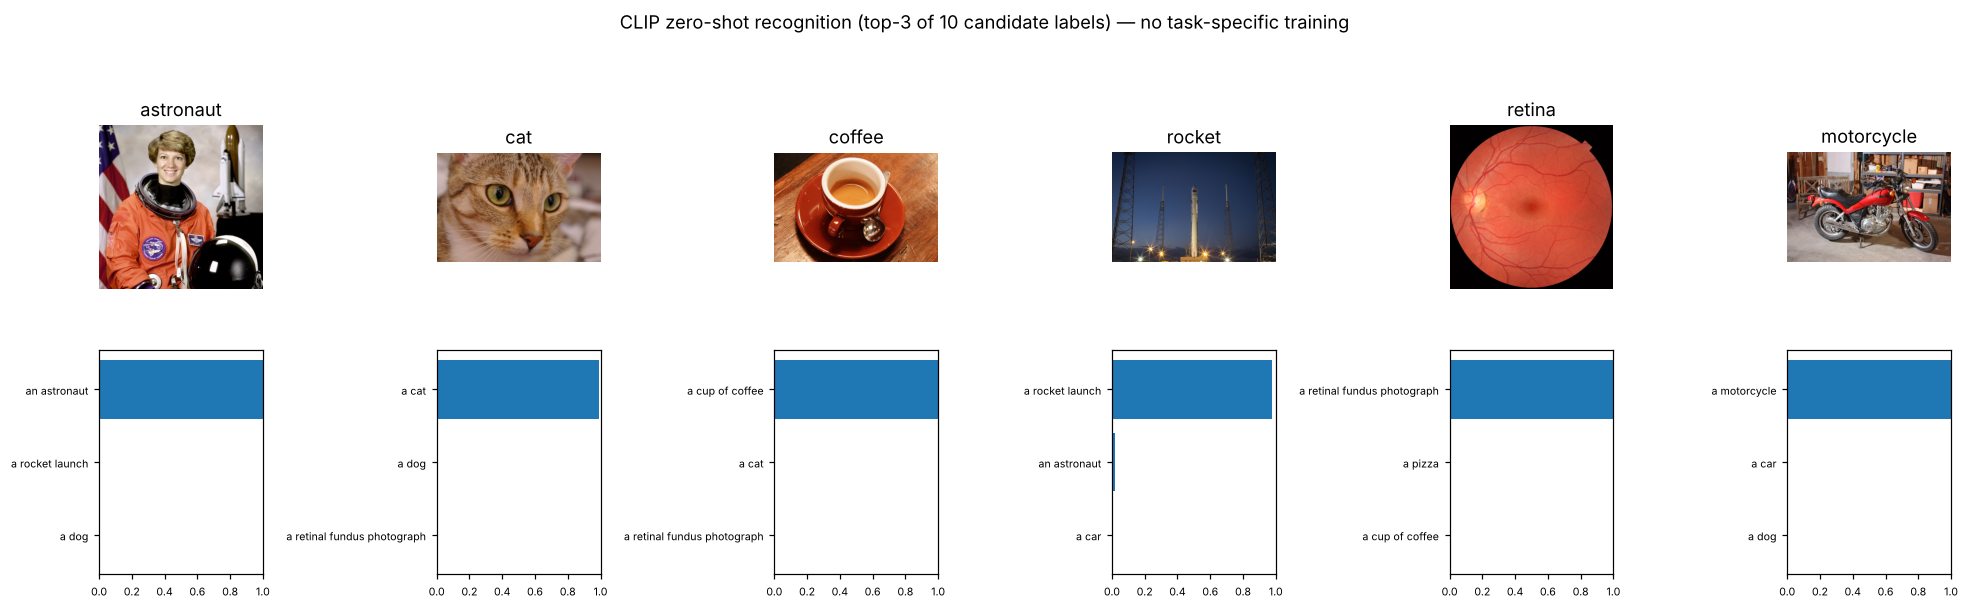

In [ ]:
# Zero-shot recognition: compare each image with 10 text prompts, softmax over the scaled similarities
probs = (clip_model.logit_scale.exp().item() * clip_image_embed(imgs) @ clip_text_embed([f"a photo of {l}" for l in LABELS]).T).softmax(-1)
fig, axes = plt.subplots(2, 6, figsize=(18, 5.6), gridspec_kw={"height_ratios": [1.2, 1]})
for i, (name, im) in enumerate(sample_images.items()):
    axes[0, i].imshow(im); axes[0, i].axis("off"); axes[0, i].set_title(name)
    top = probs[i].topk(3)
    axes[1, i].barh([LABELS[j] for j in top.indices][::-1], top.values.numpy()[::-1], color="C0")
    axes[1, i].set_xlim(0, 1); axes[1, i].tick_params(labelsize=7)
plt.suptitle("CLIP zero-shot recognition (top-3 of 10 candidate labels) — no task-specific training")
save_fig("05a_clip_zero_shot")

### 5.2 SmolVLM: a generative VLM (pretrained-backbone family)

`HuggingFaceTB/SmolVLM-500M-Instruct` follows the Idefics3 design:
* a **SigLIP** vision encoder sees 512×512 px images (or tiles), giving 32×32 = 1024 patch features;
* a **connector** applies pixel shuffle with $r=4$, giving **64 tokens per image**, followed by a linear projection;
* the **SmolLM2** language model generates the answer.

We load it in float32, which is numerically safe on every runtime and fits comfortably in a free Colab GPU or CPU. We then inspect its components and verify that its connector groups visual tokens exactly like our `pixel_shuffle` from Section 2.2.

In [ ]:
vlm_proc = AutoProcessor.from_pretrained(VLM_ID)
vlm = AutoModelForImageTextToText.from_pretrained(VLM_ID, dtype=torch.float32).to(DEVICE).eval()
core = vlm.model                                                   # vision_model, connector, text_model
r = vlm.config.scale_factor
print(f"{type(vlm).__name__}: vision encoder {count(core.vision_model) / 1e6:.0f}M | connector {count(core.connector) / 1e6:.1f}M | "
      f"language model {count(core.text_model) / 1e6:.0f}M (+ LM head) | total {count(vlm) / 1e6:.0f}M parameters")
print(f"vision: {vlm.config.vision_config.image_size}px images, patch {vlm.config.vision_config.patch_size} -> "
      f"{(vlm.config.vision_config.image_size // vlm.config.vision_config.patch_size) ** 2} patches -> pixel shuffle r={r} -> "
      f"{(vlm.config.vision_config.image_size // vlm.config.vision_config.patch_size) ** 2 // r ** 2} tokens per image")

# Verify the connector's token grouping against our implementation: feed token *indices* and compare groups
ids = torch.arange(1024, dtype=torch.float32).view(1, 1024, 1)
theirs = core.connector.pixel_shuffle(ids, r)[0].sort(dim=1).values          # [64, 16] sorted input ids per output token
mine = pixel_shuffle(ids, r)[0].sort(dim=1).values
assert torch.equal(theirs, mine)
print("Verified: SmolVLM's connector merges exactly the same 4×4 blocks of patch tokens as our pixel_shuffle().")

Idefics3ForConditionalGeneration: vision encoder 86M | connector 11.8M | language model 362M (+ LM head) | total 507M parameters
vision: 512px images, patch 16 -> 1024 patches -> pixel shuffle r=4 -> 64 tokens per image
Verified: SmolVLM's connector merges exactly the same 4×4 blocks of patch tokens as our pixel_shuffle().


**Prompting.** Every chat VLM expects its own prompt template. `apply_chat_template` inserts the `<image>` placeholder that the processor expands into the visual tokens. The helper `ask()` sends one image and one question and decodes greedily (deterministic).

`split=False` encodes the image once at 512 px (64 visual tokens). `split=True` lets the processor cut a large image into 512 px tiles plus a global view, which gives more detail at the cost of more tokens.

In [ ]:
def build_inputs(image, question, split=False):
    messages = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": question}]}]
    prompt = vlm_proc.apply_chat_template(messages, add_generation_prompt=True)
    # images_kwargs is the form every transformers version (4.5x and 5.x) honours for processor-specific options
    return vlm_proc(text=prompt, images=[image], return_tensors="pt", images_kwargs={"do_image_splitting": split}).to(DEVICE)

@torch.no_grad()
def ask(image, question, max_new_tokens=40, split=False, repetition_penalty=None):
    # Ask the generative VLM a question about one PIL image; returns the answer string.
    inputs = build_inputs(image.convert("RGB"), question, split)
    kwargs = dict(max_new_tokens=max_new_tokens, do_sample=False)
    if repetition_penalty:
        kwargs["repetition_penalty"] = repetition_penalty
    out = vlm.generate(**inputs, **kwargs)
    return vlm_proc.batch_decode(out[:, inputs["input_ids"].shape[1]:], skip_special_tokens=True)[0].strip()

# Image-token accounting and time-to-first-token (TTFT) with and without tiling
img_big = sample_images["astronaut"]
image_token_id = vlm.config.image_token_id
rows = []
for split in [False, True]:
    inp = build_inputs(img_big, "Describe the image.", split)
    n_img = int((inp["input_ids"] == image_token_id).sum())
    with torch.no_grad():
        vlm.generate(**inp, max_new_tokens=1, do_sample=False)                   # warm-up
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        t0 = time.perf_counter(); vlm.generate(**inp, max_new_tokens=1, do_sample=False)
        if DEVICE.type == "cuda": torch.cuda.synchronize()
    rows.append({"image splitting": split, "image tokens": n_img, "prompt length": inp["input_ids"].shape[1],
                 "time-to-first-token (s)": time.perf_counter() - t0})
df_ttft = pd.DataFrame(rows)
display(df_ttft.round(3))
assert df_ttft.loc[0, "image tokens"] == 64, "image splitting should be off: one 512 px view = 64 tokens"

,image splitting,image tokens,prompt length,time-to-first-token (s)
0,False,64,79,1.588
1,True,1088,1139,27.724


### 5.3 Capabilities: captioning, VQA and a healthcare image

12 generations in 46.2s


,image,caption,question,answer
0,astronaut,"A woman is wearing an orange space suit with a nameplate on her left arm that says ""NASA"". She has a helmet on and there is a large blac...","What is the person holding, and what is behind her?","The person is holding a helmet. Behind her, there are rockets on display stands."
1,cat,In the center of the picture there is a cat looking at something. The background is blurred.,What colour is the cat and what is it doing?,"The cat is brown in color, and it is looking at something."
2,coffee,A cup of coffee with a spoon sits on a saucer on top of a wooden table.,What is in the cup and what is on the saucer?,There is coffee in a cup and there is a spoon on the saucer.
3,rocket,"In an industrial setting, a rocket is being launched into the sky with four tall towers behind it lit up by artificial lights.",What is happening in this image?,"In an industrial setting, a rocket launch can be seen against the backdrop of a dark blue sky. The rocket appears to be stationary and i..."
4,retina,"A cross-sectional view of the human nasal cavity is shown, with a focus on the olfactory bulb and its associated structures. The olfacto...",What kind of medical image is this? Name two anatomical structures that are visible.,"This is an X-ray image, and the two anatomical structures visible include the brain (in red) and blood vessels (in blue)."
5,motorcycle,A red motorcycle is parked inside a garage with wooden shelves and a chair visible behind it.,What vehicle is shown and what colour is it?,A red motorcycle.


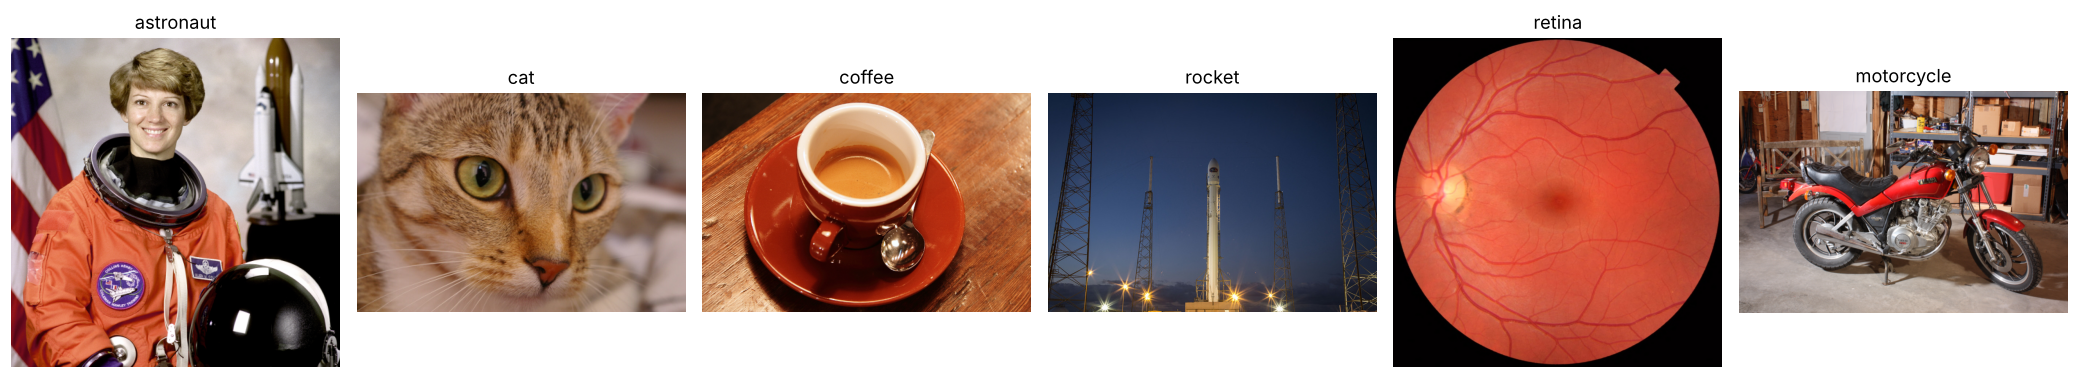

In [ ]:
QUESTIONS = {"astronaut": "What is the person holding, and what is behind her?",
             "cat": "What colour is the cat and what is it doing?",
             "coffee": "What is in the cup and what is on the saucer?",
             "rocket": "What is happening in this image?",
             "retina": "What kind of medical image is this? Name two anatomical structures that are visible.",
             "motorcycle": "What vehicle is shown and what colour is it?"}
caption_rows = []
t0 = time.time()
for name, im in sample_images.items():
    caption_rows.append({"image": name,
                         "caption": ask(im, "Describe this image in one sentence.", 40, repetition_penalty=1.15),
                         "question": QUESTIONS[name],
                         "answer": ask(im, QUESTIONS[name], 40, repetition_penalty=1.15)})
print(f"12 generations in {time.time() - t0:.1f}s")
df_caps = pd.DataFrame(caption_rows)
with pd.option_context("display.max_colwidth", 140):
    display(df_caps)

fig, axes = plt.subplots(1, 6, figsize=(19, 3.4))
for ax, (name, im) in zip(axes, sample_images.items()):
    ax.imshow(im); ax.axis("off"); ax.set_title(name)
save_fig("05b_vlm_sample_images")

**Read the outputs critically.** Generic small VLMs describe everyday scenes well, but specialised domains are a known weak spot. The check below tests whether the model recognised the **retinal fundus photograph** as an eye or retina image. Medical applications use domain-adapted models (e.g. LLaVA-Med, MedGemma) and require clinical validation; a general-purpose 500M-parameter model should never be trusted for diagnosis.

In [ ]:
retina_text = (df_caps.loc[df_caps["image"] == "retina", "caption"].iloc[0] + " " +
               df_caps.loc[df_caps["image"] == "retina", "answer"].iloc[0]).lower()
recognised = any(w in retina_text for w in ["retina", "fundus", "eye", "optic", "ophthalm"])
print("Retina caption + answer:", retina_text[:300])
print("\nDomain check:", "the model recognised an eye / retina image." if recognised else
      "the model did NOT recognise the retinal fundus photograph: a domain-shift hallucination.")

Retina caption + answer: a cross-sectional view of the human nasal cavity is shown, with a focus on the olfactory bulb and its associated structures. the olfactory bulb is visible as a small, rounded structure at the base of this is an x-ray image, and the two anatomical structures visible include the brain (in red) and blo

Domain check: the model did NOT recognise the retinal fundus photograph: a domain-shift hallucination.


### 5.4 Document understanding (OCR) and the effect of resolution

Text-rich images are where resolution matters most (FastVLM, Monkey and LLaVA-NeXT all target this). We render **realistic synthetic tax invoices**: A4 layout, seven line items, small print, random invoice numbers and totals. We ask the VLM to read the invoice number (small print) and the total (larger print), and score exact matches.

We do this **without and with image splitting**, which is the resolution / token trade-off from Section 2. Without splitting, the 1000×1300 page is shrunk to 512 px, so the small print becomes only a few pixels high.

,invoice,image splitting,true number,answer number,number correct,true total,answer total,total correct
0,0,False,INV-60494,INV-60494.,True,24190,"24,190.",True
1,0,True,INV-60494,INV-60494.,True,24190,"24,190.",True
2,1,False,INV-27611,INV-2761.,False,24190,"24,190.",True
3,1,True,INV-27611,INV-27611.,True,24190,"24,190.",True
4,2,False,INV-17412,INV-17142.,False,22391,"22,391.",True
5,2,True,INV-17412,INV-17412.,True,22391,"22,391.",True
6,3,False,INV-41190,INV-41190.,True,19175,"19,175.",True
7,3,True,INV-41190,INV-41190.,True,19175,"19,175.",True
8,4,False,INV-40939,INV-40993.,False,24987,"24,987.",True
9,4,True,INV-40939,INV-40939.,True,24987,"24,987.",True


,number correct %,total correct %
image splitting,,
False,40.0,100.0
True,100.0,100.0


Invoice-number accuracy: 40% at 512 px (64 image tokens) vs 100% with tiling (~1,000 image tokens).


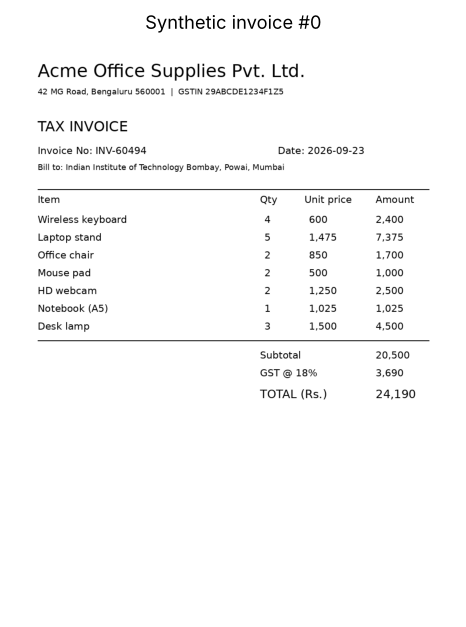

In [ ]:
FONT_PATH = font_manager.findfont("DejaVu Sans")                 # ships with matplotlib, so always available

def make_invoice(seed):
    # Render a realistic A4-style tax invoice (7 line items, small print); return (image, invoice number, total).
    rng = random.Random(seed)
    number = f"INV-{rng.randint(10000, 99999)}"
    names = ["Laptop stand", "USB-C cable", "Desk lamp", "Notebook (A5)", "Office chair", "Monitor arm", "Wireless keyboard",
             "HD webcam", "Mouse pad", "Printer paper", "Whiteboard markers", "Desk organiser"]
    items = [(n, rng.randint(1, 5), rng.randint(2, 60) * 25) for n in rng.sample(names, 7)]   # (item, qty, unit price)
    subtotal = sum(q * p for _, q, p in items); gst = round(subtotal * 0.18); total = subtotal + gst
    img = Image.new("RGB", (1000, 1300), "white"); d = ImageDraw.Draw(img)
    font = lambda size: ImageFont.truetype(FONT_PATH, size)
    d.text((60, 50), "Acme Office Supplies Pvt. Ltd.", fill="black", font=font(40))
    d.text((60, 110), "42 MG Road, Bengaluru 560001  |  GSTIN 29ABCDE1234F1Z5", fill="black", font=font(18))
    d.text((60, 180), "TAX INVOICE", fill="black", font=font(32))
    d.text((60, 240), f"Invoice No: {number}", fill="black", font=font(22))
    d.text((600, 240), f"Date: 2026-{rng.randint(1, 12):02d}-{rng.randint(1, 28):02d}", fill="black", font=font(22))
    d.text((60, 280), "Bill to: Indian Institute of Technology Bombay, Powai, Mumbai", fill="black", font=font(18))
    y = 350; d.line((60, y - 10, 940, y - 10), fill="black", width=2)
    for x_, t_ in [(60, "Item"), (560, "Qty"), (660, "Unit price"), (820, "Amount")]:
        d.text((x_, y), t_, fill="black", font=font(22))
    y += 45
    for n, q, p in items:
        for x_, t_ in [(60, n), (570, str(q)), (670, f"{p:,}"), (820, f"{q * p:,}")]:
            d.text((x_, y), t_, fill="black", font=font(22))
        y += 40
    d.line((60, y + 5, 940, y + 5), fill="black", width=2); y += 25
    d.text((560, y), "Subtotal", fill="black", font=font(22)); d.text((820, y), f"{subtotal:,}", fill="black", font=font(22)); y += 40
    d.text((560, y), "GST @ 18%", fill="black", font=font(22)); d.text((820, y), f"{gst:,}", fill="black", font=font(22)); y += 45
    d.text((560, y), "TOTAL (Rs.)", fill="black", font=font(26)); d.text((820, y), f"{total:,}", fill="black", font=font(26))
    return img, number, total

def digits(s):
    return re.sub(r"\D", "", s)

ocr_rows = []
for seed in range(5):
    inv, number, total = make_invoice(seed)
    for split in [False, True]:
        a_num = ask(inv, "What is the invoice number? Answer with the number only.", 16, split)
        a_tot = ask(inv, "What is the total amount? Answer with the number only.", 12, split)
        ocr_rows.append({"invoice": seed, "image splitting": split, "true number": number, "answer number": a_num,
                         "number correct": digits(number) in digits(a_num), "true total": total, "answer total": a_tot,
                         "total correct": str(total) == digits(a_tot)})
df_ocr = pd.DataFrame(ocr_rows)
display(df_ocr)
display(df_ocr.groupby("image splitting")[["number correct", "total correct"]].mean().mul(100).round(1)
        .rename(columns=lambda c: c + " %"))
ocr_acc = df_ocr.groupby("image splitting")["number correct"].mean() * 100
print(f"Invoice-number accuracy: {ocr_acc[False]:.0f}% at 512 px (64 image tokens) vs {ocr_acc[True]:.0f}% with tiling (~1,000 image tokens).")
plt.figure(figsize=(4.5, 5.8)); plt.imshow(make_invoice(0)[0]); plt.axis("off"); plt.title("Synthetic invoice #0")
save_fig("05c_invoice_example")

### 5.5 Chart understanding

,chart,truth,answer,correct
0,0,Jan,Jan.,True
1,1,May,May.,True
2,2,Mar,March.,True
3,3,Jun,June.,True
4,4,Jun,Jun.,True
5,5,Apr,Apr.,True


Chart QA accuracy: 100%


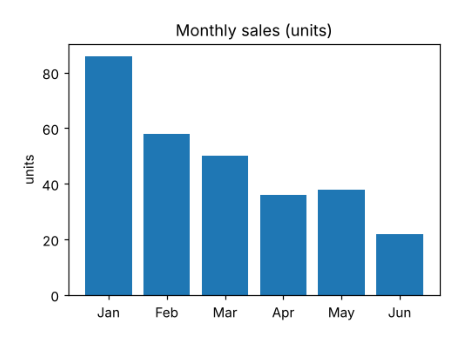

In [ ]:
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun"]
def make_chart(seed):
    # Bar chart of monthly sales with a unique maximum; returns (image, month with the highest bar).
    rng = np.random.default_rng(seed)
    vals = rng.integers(20, 80, size=6).astype(int); best = int(rng.integers(0, 6)); vals[best] = vals.max() + 15
    fig, ax = plt.subplots(figsize=(5, 3.4), dpi=110)
    ax.bar(MONTHS, vals, color="tab:blue"); ax.set_title("Monthly sales (units)"); ax.set_ylabel("units")
    buf = io.BytesIO(); fig.savefig(buf, format="png", bbox_inches="tight"); plt.close(fig)
    return Image.open(buf).convert("RGB"), MONTHS[best]

chart_rows = []
for seed in range(6):
    chart, best = make_chart(seed)
    ans = ask(chart, "Which month has the highest sales? Answer with the month only.", 6)
    chart_rows.append({"chart": seed, "truth": best, "answer": ans, "correct": best.lower() in ans.lower()})
df_chart = pd.DataFrame(chart_rows)
display(df_chart)
print(f"Chart QA accuracy: {df_chart['correct'].mean() * 100:.0f}%")
plt.figure(figsize=(4.5, 3.2)); plt.imshow(make_chart(0)[0]); plt.axis("off"); save_fig("05d_chart_example")

### 5.6 Object hallucination: a POPE-style probe

**POPE** (Li et al., 2023) asks yes/no questions "Is there a ⟨object⟩ in the image?", half about objects that **are** present and half about objects that are **absent**. A model that tends to say "yes" to absent objects is hallucinating. We report accuracy, the yes-ratio (ideal 50%), and the hallucination rate on absent objects.

In [ ]:
POPE = {"astronaut": (["person", "flag"], ["dog", "bicycle"]),
        "cat":       (["cat"], ["dog", "car"]),
        "coffee":    (["cup", "spoon"], ["laptop", "banana"]),
        "rocket":    (["rocket", "smoke"], ["horse", "umbrella"]),
        "motorcycle": (["motorcycle"], ["giraffe", "pizza"])}
pope_rows = []
for name, (present, absent) in POPE.items():
    for obj, truth in [(o, "yes") for o in present] + [(o, "no") for o in absent]:
        ans = ask(sample_images[name], f"Is there a {obj} in the image? Answer yes or no.", 3).lower()
        said_yes = ans.startswith("yes")
        pope_rows.append({"image": name, "object": obj, "truth": truth, "answer": ans, "said yes": said_yes,
                          "correct": said_yes == (truth == "yes")})
df_pope = pd.DataFrame(pope_rows)
pope_summary = {"accuracy %": df_pope["correct"].mean() * 100,
                "yes-ratio %": df_pope["said yes"].mean() * 100,
                "hallucination rate on absent objects %": df_pope.loc[df_pope["truth"] == "no", "said yes"].mean() * 100,
                "recall on present objects %": df_pope.loc[df_pope["truth"] == "yes", "said yes"].mean() * 100}
display(df_pope)
display(pd.Series(pope_summary).round(1).to_frame("value"))

,image,object,truth,answer,said yes,correct
0,astronaut,person,yes,yes.,True,True
1,astronaut,flag,yes,yes.,True,True
2,astronaut,dog,no,no.,False,True
3,astronaut,bicycle,no,no.,False,True
4,cat,cat,yes,yes.,True,True
5,cat,dog,no,no.,False,True
6,cat,car,no,no.,False,True
7,coffee,cup,yes,yes.,True,True
8,coffee,spoon,yes,yes.,True,True
9,coffee,laptop,no,no.,False,True


,value
accuracy %,94.4
yes-ratio %,38.9
hallucination rate on absent objects %,0.0
recall on present objects %,87.5


## 6. Use case: AI-powered catalog onboarding for a fashion marketplace

**The business problem.** An Indian fashion e-commerce marketplace onboards thousands of new products every day from many sellers. Each listing needs:
* a **category** (product type);
* **attributes** such as colour;
* a **description**;
* **search-ability**: customers type queries like *"red party dress"*;
* **recommendations** ("similar items").

Seller-supplied metadata is often **missing or wrong**. Manual tagging is slow and expensive, and supervised classifiers need labelled data for every new category.

**The VLM solution** combines both families from this notebook:

| Need | VLM technique | Section |
|---|---|---|
| Categorise new products with no training labels | CLIP zero-shot classification + prompt engineering | 6.2 |
| Improve with a few labelled examples | Linear probe on CLIP embeddings (few-shot) | 6.3 |
| Tag colour | CLIP zero-shot attribute tagging | 6.4 |
| Natural-language search | CLIP text → image retrieval | 6.5 |
| "You may also like" | CLIP image → image similarity | 6.6 |
| Catch wrong seller labels | Image–label agreement score (data-quality audit) | 6.7 |
| Attribute extraction and descriptions | Generative VLM (SmolVLM) + grounding against hallucination | 6.8 |
| One API for new listings | `onboard_product()` pipeline | 6.9 |

**Data.** The *Fashion Product Images (small)* dataset (Aggarwal, Kaggle; mirrored on Hugging Face as `ashraq/fashion-product-images-small`). It contains real catalogue photos from the Indian retailer Myntra with seller-entered labels (master category, sub-category, article type, base colour, gender, season, usage, product title). We use one of its two files: **22,036 products**.

22,036 products, columns: ['id', 'gender', 'masterCategory', 'subCategory', 'articleType', 'baseColour', 'season', 'year', 'usage', 'productDisplayName']


Working set: 2,500 products, 25 product types × 100. Image size: (60, 80)


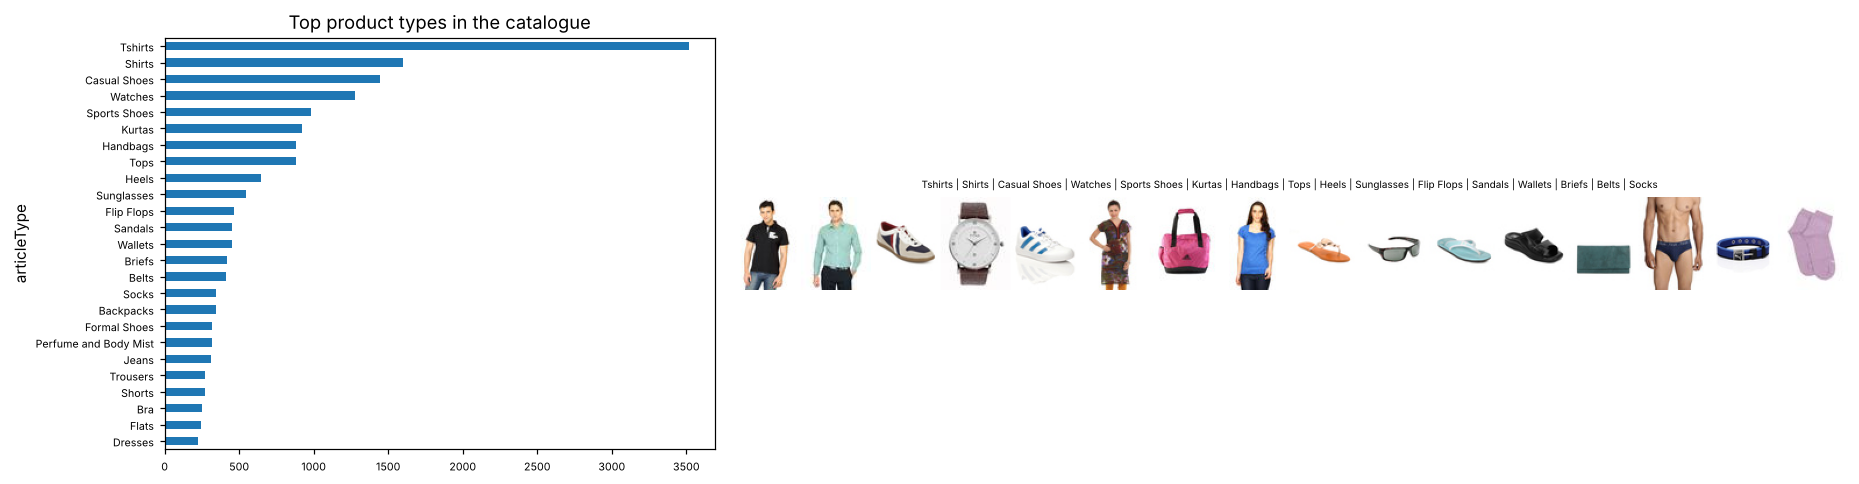

In [ ]:
parquet_path = hf_hub_download(DATASET[0], DATASET[1], repo_type="dataset")
catalog = pd.read_parquet(parquet_path)
print(f"{len(catalog):,} products, columns: {[c for c in catalog.columns if c != 'image']}")

TOP_TYPES = catalog["articleType"].value_counts().head(N_CLASSES).index.tolist()
products = pd.concat([catalog[catalog["articleType"] == t].sample(n=min(N_PER_CLASS, int((catalog["articleType"] == t).sum())),
                                                                   random_state=SEED) for t in TOP_TYPES]).reset_index(drop=True)
products["pil"] = [Image.open(io.BytesIO(b["bytes"])).convert("RGB") for b in products["image"]]   # decode JPEG bytes
y_type = torch.tensor([TOP_TYPES.index(t) for t in products["articleType"]])
print(f"Working set: {len(products):,} products, {N_CLASSES} product types × {N_PER_CLASS}. Image size: {products['pil'][0].size}")

fig = plt.figure(figsize=(17, 4.5))
ax = fig.add_subplot(1, 3, 1)
catalog["articleType"].value_counts().head(N_CLASSES)[::-1].plot.barh(ax=ax, fontsize=7, color="C0"); ax.set_title("Top product types in the catalogue")
ax = fig.add_subplot(1, 3, (2, 3))
idx = [products.index[products["articleType"] == t][0] for t in TOP_TYPES[:16]]
strip = np.concatenate([np.asarray(products["pil"][i].resize((60, 80))) for i in idx], axis=1)
ax.imshow(strip); ax.axis("off"); ax.set_title(" | ".join(TOP_TYPES[:16]), fontsize=6.5)
save_fig("06a_catalog_overview")

### 6.1 Building the embedding index

Every product image is embedded **once** with CLIP's image tower, giving 512-d unit vectors. All the tasks below (classification, tagging, search, recommendations, quality audit) reuse this single index. Only small text embeddings are computed per task. This is why contrastive VLMs are cheap to deploy at catalogue scale.

In [ ]:
t0 = time.time()
IMG = clip_image_embed(products["pil"].tolist())
print(f"Embedded {len(IMG):,} product images in {time.time() - t0:.1f}s  ->  index shape {tuple(IMG.shape)}")

Embedded 2,500 product images in 123.9s  ->  index shape (2500, 512)


### 6.2 Zero-shot product categorisation and prompt engineering

For each product type we write a text prompt, embed it, and assign every image to the most similar prompt. **No labelled data is used.** The prompt matters: CLIP was trained on natural captions, so we compare four strategies:
1. the raw catalogue label (`"Tshirts"`);
2. a cleaned natural name (`"t-shirt"`);
3. `"a photo of a t-shirt"`;
4. **prompt ensembling**: averaging the embeddings of five templates (Radford et al., 2021).

In [ ]:
NICE = {"Tshirts": "t-shirt", "Shirts": "shirt", "Casual Shoes": "casual shoes", "Watches": "wrist watch", "Sports Shoes": "sports shoes",
        "Kurtas": "kurta", "Handbags": "handbag", "Tops": "women's top", "Heels": "high heels", "Sunglasses": "sunglasses",
        "Flip Flops": "flip flops", "Sandals": "sandals", "Wallets": "wallet", "Briefs": "men's briefs underwear", "Belts": "belt",
        "Socks": "socks", "Backpacks": "backpack", "Formal Shoes": "formal leather shoes", "Perfume and Body Mist": "perfume bottle",
        "Jeans": "jeans", "Trousers": "trousers", "Shorts": "shorts", "Bra": "bra", "Flats": "women's flat shoes", "Dresses": "dress",
        "Sarees": "saree", "Earrings": "earrings", "Deodorant": "deodorant spray", "Caps": "cap", "Track Pants": "track pants"}
nice = lambda t: NICE.get(t, t.lower())
TEMPLATES = ["a photo of a {}.", "a product photo of a {}, from an online fashion store.", "an e-commerce catalog image of a {}.",
             "a {} on a plain white background.", "a close-up photo of a {}."]

def class_embeddings(names, templates):
    # One text embedding per class: average over templates, then re-normalise (prompt ensembling).
    return F.normalize(torch.stack([clip_text_embed([t.format(n) for t in templates]).mean(0) for n in names]), dim=-1)

def accuracy(scores, y):
    return (scores.argmax(1) == y).float().mean().item() * 100

def top5(scores, y):
    return (scores.topk(5, dim=1).indices == y[:, None]).any(1).float().mean().item() * 100

strategies = {"1. raw label": clip_text_embed(TOP_TYPES),
              "2. clean name": clip_text_embed([nice(t) for t in TOP_TYPES]),
              "3. 'a photo of a …'": clip_text_embed([f"a photo of a {nice(t)}." for t in TOP_TYPES]),
              "4. ensemble of 5 templates": class_embeddings([nice(t) for t in TOP_TYPES], TEMPLATES)}
df_prompts = pd.DataFrame({name: {"top-1 accuracy %": accuracy(IMG @ T.T, y_type), "top-5 accuracy %": top5(IMG @ T.T, y_type)}
                           for name, T in strategies.items()}).T
display(df_prompts.round(2))
print(f"Chance level: {100 / N_CLASSES:.1f}% top-1.")
TYPE_EMB = strategies["4. ensemble of 5 templates"]

,top-1 accuracy %,top-5 accuracy %
1. raw label,71.64,94.20
2. clean name,64.80,95.72
3. 'a photo of a …',78.24,97.76
4. ensemble of 5 templates,79.92,98.20


Chance level: 4.0% top-1.


Prompt wording alone moves zero-shot accuracy by many points, with no change to the model. Wrapping the class name in a caption-like template (*"a photo of a …"*) matters most, because that resembles CLIP's web-caption training data. Ensembling several templates adds a little more. A cleaned-up name on its own is not automatically better than the raw label.

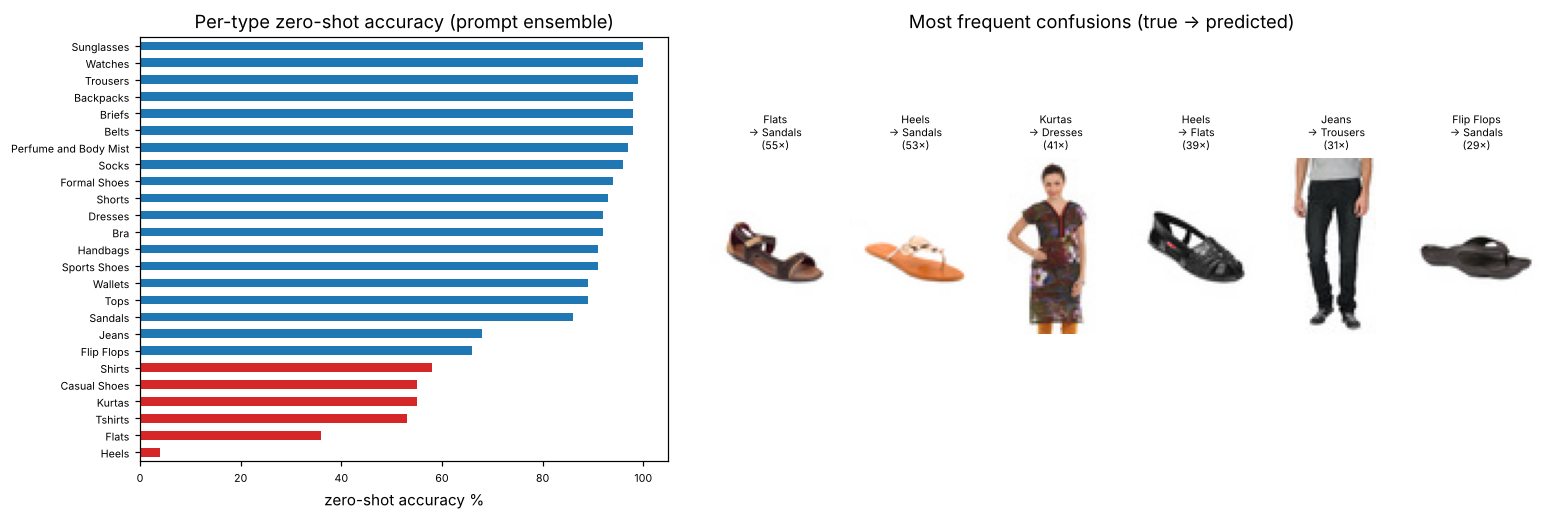

In [ ]:
pred_type = (IMG @ TYPE_EMB.T).argmax(1)
per_class = pd.Series({t: (pred_type[y_type == k] == k).float().mean().item() * 100 for k, t in enumerate(TOP_TYPES)}).sort_values()
conf = pd.crosstab(pd.Series([TOP_TYPES[i] for i in y_type], name="true"), pd.Series([TOP_TYPES[i] for i in pred_type], name="pred"))
pairs_conf = [(t, p, conf.loc[t, p]) for t in conf.index for p in conf.columns if t != p and conf.loc[t, p] > 0]
top_conf = sorted(pairs_conf, key=lambda z: -z[2])[:6]

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 1.2]})
per_class.plot.barh(ax=axes[0], color=["C3" if v < 60 else "C0" for v in per_class], fontsize=7)
axes[0].set_xlabel("zero-shot accuracy %"); axes[0].set_title("Per-type zero-shot accuracy (prompt ensemble)")
axes[1].axis("off"); axes[1].set_title("Most frequent confusions (true → predicted)")
for k, (t, p, c) in enumerate(top_conf):
    ex = products.index[(products["articleType"] == t) & (pred_type.numpy() == TOP_TYPES.index(p))][0]
    sub_ax = fig.add_axes([0.47 + 0.085 * k, 0.25, 0.08, 0.5])
    sub_ax.imshow(products["pil"][ex]); sub_ax.axis("off"); sub_ax.set_title(f"{t}\n→ {p}\n({c}×)", fontsize=7)
plt.savefig(OUTPUT_DIR / "06b_zero_shot_per_class.png", bbox_inches="tight"); plt.show()

Most errors are between **visually and semantically adjacent types**, such as casual vs sports vs formal shoes, sandals vs flip-flops, or tops vs t-shirts. Even a human tagger needs care with these, and the catalogue labels themselves are not always consistent.

### 6.3 Few-shot adaptation: linear probe on CLIP embeddings

When a few labelled examples per type are available, we can train a logistic-regression classifier on the frozen CLIP image embeddings (a "linear probe"). Half the products are used for (subsampled) training and half for testing, and we compare $k$-shot probes with zero-shot CLIP on the **same** test half. This shows how many labels are needed to beat a model that needs **zero**.

,labelled examples per type,linear-probe accuracy %
0,1,69.04
1,2,77.84
2,4,79.44
3,8,83.04
4,16,86.00
5,32,87.12
6,50,86.96


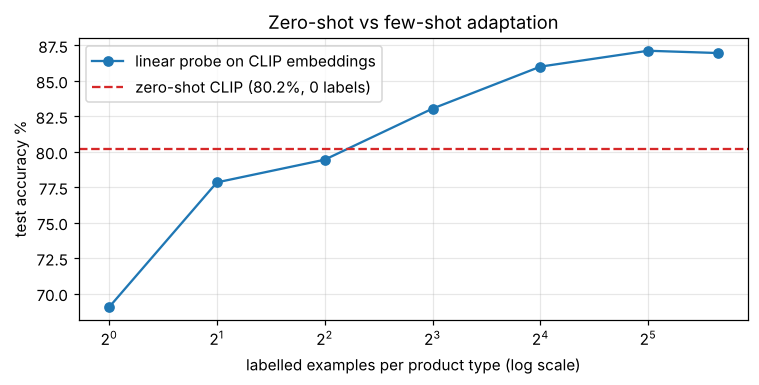

In [ ]:
rng = np.random.default_rng(SEED)
order = rng.permutation(len(products)); tr_idx, te_idx = order[: len(order) // 2], order[len(order) // 2:]
X_np, y_np = IMG.numpy(), y_type.numpy()
zero_shot_test = accuracy(IMG[te_idx] @ TYPE_EMB.T, y_type[te_idx])
probe_rows = []
for k in [1, 2, 4, 8, 16, 32]:
    sel = np.concatenate([tr_idx[y_np[tr_idx] == c][:k] for c in range(N_CLASSES)])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UserWarning)                # k=1 gives one sample per class; sklearn warns, harmlessly
        clf = LogisticRegression(max_iter=3000, C=10.0).fit(X_np[sel], y_np[sel])
    probe_rows.append({"labelled examples per type": k, "linear-probe accuracy %": (clf.predict(X_np[te_idx]) == y_np[te_idx]).mean() * 100})
clf_full = LogisticRegression(max_iter=3000, C=10.0).fit(X_np[tr_idx], y_np[tr_idx])
probe_rows.append({"labelled examples per type": int(len(tr_idx) / N_CLASSES), "linear-probe accuracy %": (clf_full.predict(X_np[te_idx]) == y_np[te_idx]).mean() * 100})
df_probe = pd.DataFrame(probe_rows)
display(df_probe.round(2))

plt.figure(figsize=(7, 3.6))
plt.semilogx(df_probe["labelled examples per type"], df_probe["linear-probe accuracy %"], "o-", base=2, label="linear probe on CLIP embeddings")
plt.axhline(zero_shot_test, color="C3", ls="--", label=f"zero-shot CLIP ({zero_shot_test:.1f}%, 0 labels)")
plt.xlabel("labelled examples per product type (log scale)"); plt.ylabel("test accuracy %"); plt.legend(); plt.grid(alpha=0.3, which="both")
plt.title("Zero-shot vs few-shot adaptation"); save_fig("06c_few_shot_probe")

### 6.4 Zero-shot colour tagging

The same approach tags attributes. We restrict to the 12 most common basic colours, prompt with `"a photo of a {colour} {product type}"`, using the *predicted* type so that no labels are needed, and compare against the seller's colour label.

In [ ]:
COLOURS12 = ["Black", "White", "Blue", "Brown", "Grey", "Red", "Green", "Pink", "Navy Blue", "Purple", "Yellow", "Orange"]
has_basic = products["baseColour"].isin(COLOURS12).to_numpy()
col_idx = np.where(has_basic)[0]
y_col = torch.tensor([COLOURS12.index(c) for c in products["baseColour"][col_idx]])

# Colour prompts are conditioned on the predicted product type: one set of 12 prompts per type, computed once
colour_emb_by_type = {k: clip_text_embed([f"a photo of a {c.lower()} {nice(t)}." for c in COLOURS12]) for k, t in enumerate(TOP_TYPES)}
col_pred = torch.tensor([int((IMG[i] @ colour_emb_by_type[int(pred_type[i])].T).argmax()) for i in col_idx])
FAMILY = {"Navy Blue": "Blue"}                                       # navy counts as blue for the "family" metric
fam = lambda c: FAMILY.get(c, c)
colour_acc = (col_pred == y_col).float().mean().item() * 100
colour_acc_family = np.mean([fam(COLOURS12[p]) == fam(COLOURS12[t]) for p, t in zip(col_pred.tolist(), y_col.tolist())]) * 100
print(f"Products with a basic colour label: {len(col_idx):,}")
print(f"CLIP zero-shot colour accuracy: {colour_acc:.1f}%  (treating navy as blue: {colour_acc_family:.1f}%)   chance: {100 / 12:.1f}%")

Products with a basic colour label: 2,115
CLIP zero-shot colour accuracy: 57.3%  (treating navy as blue: 62.0%)   chance: 8.3%


### 6.5 Natural-language product search (text → image retrieval)

Customers search in free text. We embed the query, rank all product images by cosine similarity and show the top results.

**Quantitative evaluation** uses each product's own catalogue title (e.g. *"Puma Men Black Sports Shoes"*) as a query:
* **Recall@K:** is that exact product in the top $K$ of 2,500?
* **Type-precision@5 / colour-precision@5:** what fraction of the top-5 results have the queried product type / colour? Shoppers care about getting *relevant* items, not one specific item.

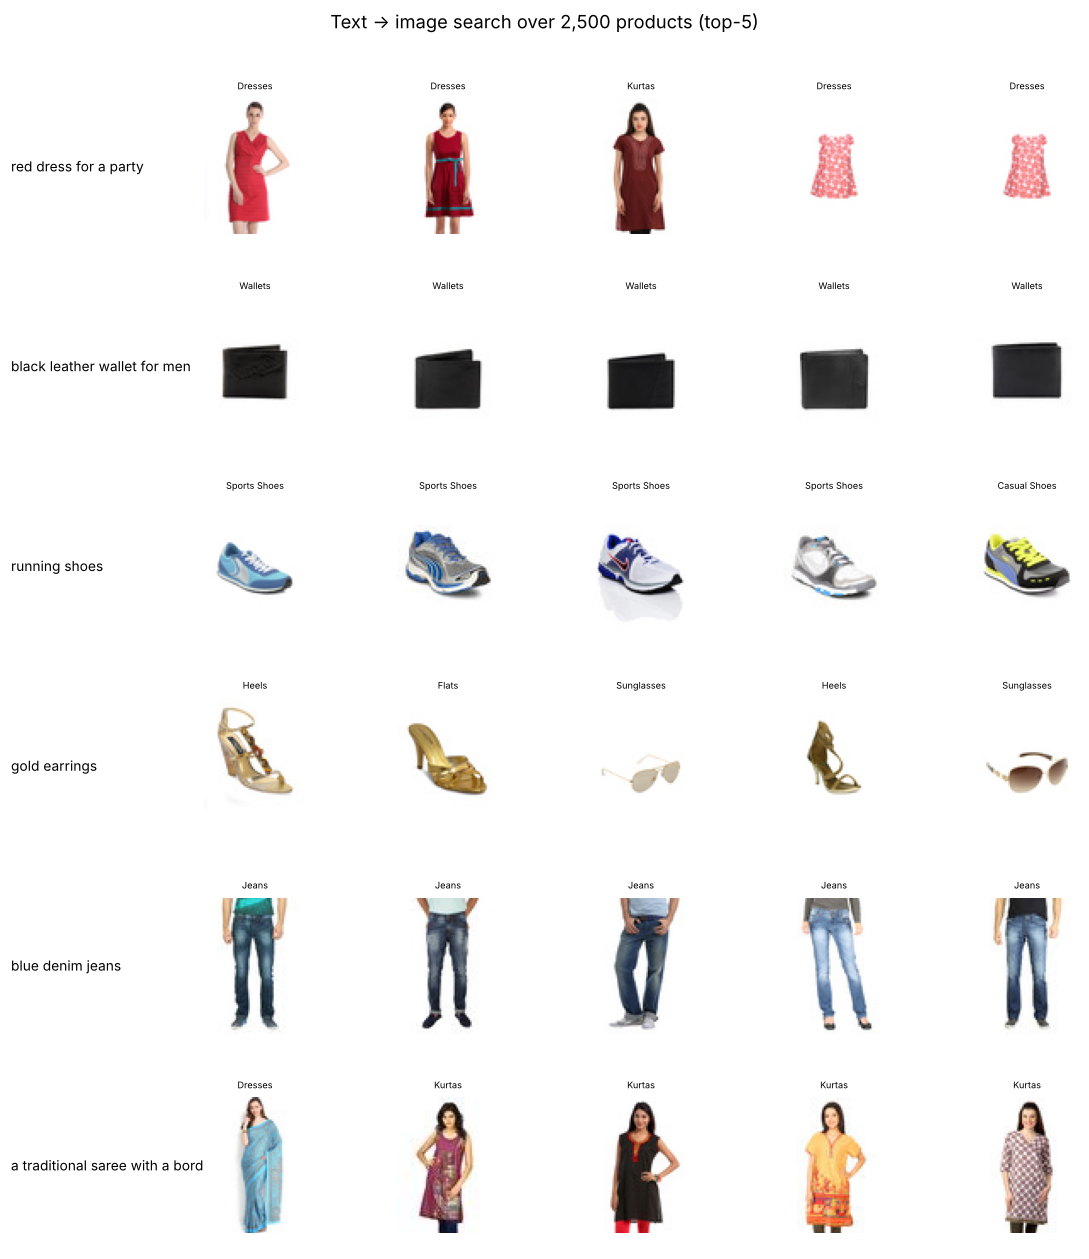

,"product-title queries (2,500)"
Recall@1 %,11.4
Recall@5 %,34.3
Recall@10 %,49.0
type-precision@5 %,82.1
colour-precision@5 %,57.2


Random ranking would give Recall@1 = 0.04% and type-precision@5 = 4%.


In [ ]:
QUERIES = ["red dress for a party", "black leather wallet for men", "running shoes", "gold earrings",
           "blue denim jeans", "a traditional saree with a border"]
Q_EMB = clip_text_embed(QUERIES)
fig, axes = plt.subplots(len(QUERIES), 6, figsize=(10, 1.9 * len(QUERIES)))
for r_, q in enumerate(QUERIES):
    best = (IMG @ Q_EMB[r_]).topk(5).indices
    axes[r_, 0].text(0, 0.5, q, fontsize=9, va="center", wrap=True); axes[r_, 0].axis("off")
    for c_, j in enumerate(best.tolist()):
        axes[r_, c_ + 1].imshow(products["pil"][j]); axes[r_, c_ + 1].axis("off")
        axes[r_, c_ + 1].set_title(products["articleType"][j], fontsize=6)
plt.suptitle("Text → image search over 2,500 products (top-5)", y=1.0)
save_fig("06d_text_search")

TITLE_EMB = clip_text_embed(products["productDisplayName"].tolist())
S = TITLE_EMB @ IMG.T                                                  # [queries, products]
rank = (S > S.diag()[:, None]).sum(1)                                  # 0 = the product itself is ranked first
top5_idx = S.topk(5, dim=1).indices
types_arr, colours_arr = products["articleType"].to_numpy(), products["baseColour"].to_numpy()
search_metrics = {f"Recall@{k} %": (rank < k).float().mean().item() * 100 for k in [1, 5, 10]}
search_metrics["type-precision@5 %"] = np.mean(types_arr[top5_idx.numpy()] == types_arr[:, None]) * 100
search_metrics["colour-precision@5 %"] = np.mean(colours_arr[top5_idx.numpy()] == colours_arr[:, None]) * 100
display(pd.Series(search_metrics).round(1).to_frame("product-title queries (2,500)"))
print(f"Random ranking would give Recall@1 = {100 / len(products):.2f}% and type-precision@5 = {100 / N_CLASSES:.0f}%.")

**Two instructive search results.**
* *"gold earrings"* returns gold heels and sunglasses. Earrings are **not** among the 25 product types in this working set, and a vector search always returns its nearest neighbours, so it falls back to gold-coloured items. Production search adds a similarity threshold or a "no exact match" fallback.
* For *"a traditional saree with a border"*, the first hit is a saree that the seller labelled as a dress (sarees are also outside the 25 types). CLIP's open vocabulary still finds it, and the mislabel is the kind of error that the audit in Section 6.7 is designed to catch.

### 6.6 "You may also like": visual similarity recommendations (image → image)

Image→image recommendations: same type in top-5 = 82.1%, same colour = 37.0%


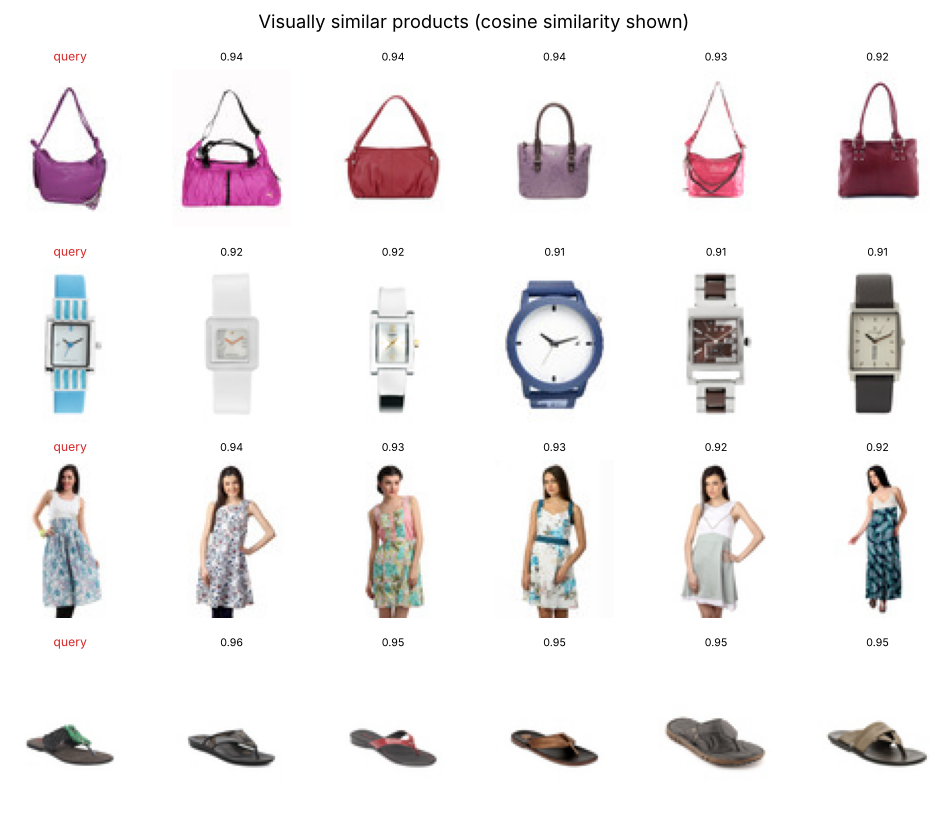

In [ ]:
SIM = IMG @ IMG.T
SIM.fill_diagonal_(-1)                                                 # never recommend the product itself
nn5 = SIM.topk(5, dim=1).indices.numpy()
rec_type_p5 = np.mean(types_arr[nn5] == types_arr[:, None]) * 100
rec_col_p5 = np.mean(colours_arr[nn5] == colours_arr[:, None]) * 100
print(f"Image→image recommendations: same type in top-5 = {rec_type_p5:.1f}%, same colour = {rec_col_p5:.1f}%")

anchors = [int(products.index[products["articleType"] == t][3]) for t in ["Handbags", "Watches", "Kurtas", "Heels"]]
fig, axes = plt.subplots(len(anchors), 6, figsize=(9, 1.9 * len(anchors)))
for r_, a in enumerate(anchors):
    axes[r_, 0].imshow(products["pil"][a]); axes[r_, 0].set_title("query", fontsize=8, color="C3")
    for c_, j in enumerate(nn5[a]):
        axes[r_, c_ + 1].imshow(products["pil"][j]); axes[r_, c_ + 1].set_title(f"{SIM[a, j]:.2f}", fontsize=7)
    for ax in axes[r_]: ax.axis("off")
plt.suptitle("Visually similar products (cosine similarity shown)")
save_fig("06e_similar_items")

### 6.7 Catalogue quality audit: detecting wrong seller labels

Wrong product types hurt search and the customer experience. We simulate a realistic audit:
1. **corrupt 5%** of the labels with a random wrong type;
2. score every listing by how much CLIP *disagrees* with its label, $1 - p_{\text{CLIP}}(\text{label}\mid\text{image})$;
3. measure how well the score ranks the corrupted listings first.

We report the **AUROC** and the **precision of the top-$k$ flagged listings**, which is what a human reviewer would see.

Corrupted listings: 118 of 2500  |  AUROC = 0.989  |  precision of the top-118 flagged = 76.3%


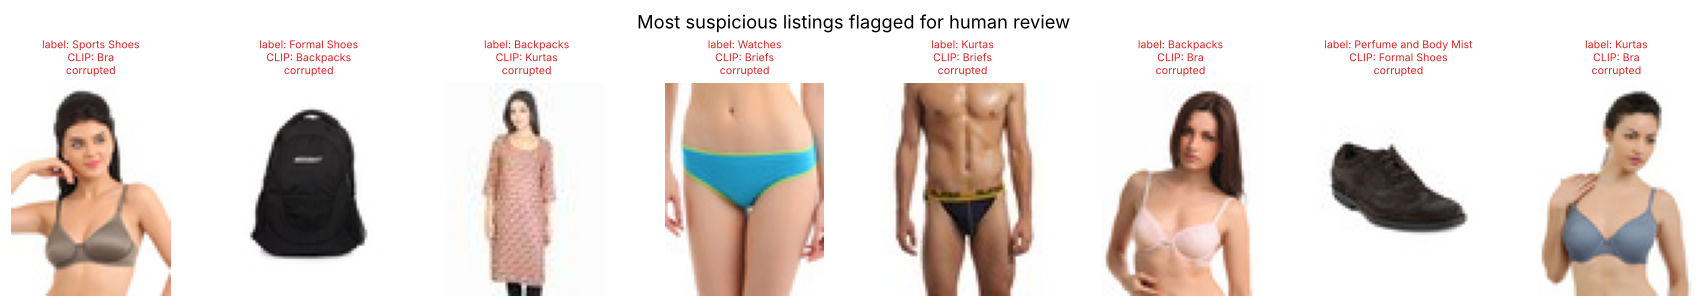

In [ ]:
rng = np.random.default_rng(SEED)
is_noisy = rng.random(len(products)) < 0.05
noisy_label = y_type.clone()
for i in np.where(is_noisy)[0]:
    noisy_label[i] = int((y_type[i] + rng.integers(1, N_CLASSES)) % N_CLASSES)     # a different, wrong type

p_label = (clip_model.logit_scale.exp().item() * IMG @ TYPE_EMB.T).softmax(1)
suspicion = 1 - p_label[torch.arange(len(products)), noisy_label]
auroc = roc_auc_score(is_noisy, suspicion.numpy())
k = int(is_noisy.sum())
flagged = suspicion.topk(k).indices.numpy()
precision_at_k = is_noisy[flagged].mean() * 100
print(f"Corrupted listings: {k} of {len(products)}  |  AUROC = {auroc:.3f}  |  precision of the top-{k} flagged = {precision_at_k:.1f}%")

fig, axes = plt.subplots(1, 8, figsize=(16, 2.8))
for ax, j in zip(axes, flagged[:8]):
    ax.imshow(products["pil"][j]); ax.axis("off")
    ax.set_title(f"label: {TOP_TYPES[noisy_label[j]]}\nCLIP: {TOP_TYPES[p_label[j].argmax()]}\n{'corrupted' if is_noisy[j] else 'original label'}",
                 fontsize=7, color="C3" if is_noisy[j] else "C2")
plt.suptitle("Most suspicious listings flagged for human review")
save_fig("06f_label_audit")

### 6.8 Generative VLM for listing enrichment: attributes, descriptions and hallucination

CLIP can only *choose among* labels we provide. A **generative** VLM can *answer* and *write*. We evaluate SmolVLM on a random sample of products in two parts.

**(a) Attribute extraction:**
* the colour asked **open-ended** vs **constrained** (the 12 allowed colours listed in the prompt), compared with CLIP's zero-shot colour on the same products;
* the product type, asked open-ended (judged by matching keywords).

**(b) Description generation, free vs grounded:**
* **Free prompt:** "Write a short product description."
* **Grounded prompt:** the product type predicted by CLIP and the colour extracted by the VLM's constrained question (the better-performing extractors on this sample) are given in the prompt, with the instruction to describe only visible details and not invent brands.

We measure quality and hallucination in three ways:
* **CLIPScore** (Hessel et al., 2021), $2.5\cdot\max(\cos(\text{image},\text{text}),0)$, a reference-free image–text alignment score;
* **main colour stated correctly**: the first colour word in the description matches the seller's colour label. Secondary colours such as "silver strap" are allowed;
* **generic boilerplate**: the text describes the store ("Welcome to our online store…") rather than the product.

In [ ]:
vlm_sample = products.iloc[col_idx].sample(n=N_VLM_EVAL, random_state=1)
COLOUR_WORDS = [c.lower() for c in COLOURS12] + ["gray", "navy", "beige", "maroon", "gold", "silver", "cream", "olive"]

def normalise_colour(ans):
    a = ans.lower().replace("gray", "grey")
    for c in sorted(COLOURS12, key=len, reverse=True):              # longest match first ("navy blue" before "blue")
        if c.lower() in a:
            return c
    return a.strip(" .")[:20]

TYPE_KEYWORDS = {"Tshirts": ["t-shirt", "tshirt", "t shirt", "tee"], "Shirts": ["shirt"], "Casual Shoes": ["shoe", "sneaker"],
                 "Watches": ["watch"], "Sports Shoes": ["shoe", "sneaker", "trainer"], "Kurtas": ["kurta", "tunic", "dress", "shirt", "top"],
                 "Handbags": ["bag", "purse"], "Tops": ["top", "shirt", "blouse"], "Heels": ["heel", "shoe", "sandal"],
                 "Sunglasses": ["sunglass", "glasses"], "Flip Flops": ["flip", "slipper", "sandal"], "Sandals": ["sandal", "slipper"],
                 "Wallets": ["wallet", "purse"], "Briefs": ["brief", "underwear", "boxer", "short"], "Belts": ["belt"], "Socks": ["sock"],
                 "Backpacks": ["backpack", "bag"], "Formal Shoes": ["shoe"], "Perfume and Body Mist": ["perfume", "spray", "fragrance", "bottle", "deodorant"],
                 "Jeans": ["jean", "pant", "denim", "trouser"], "Trousers": ["trouser", "pant"], "Shorts": ["short"], "Bra": ["bra"],
                 "Flats": ["shoe", "flat", "sandal", "slipper"], "Dresses": ["dress", "gown"]}

options = ", ".join(c.lower() for c in COLOURS12)
attr_rows = []
t0 = time.time()
for i, row in vlm_sample.iterrows():
    img = row["pil"]
    free = ask(img, "What is the main colour of this product? Answer with one word.", 6)
    constrained = ask(img, f"What is the main colour of this product? Choose one of: {options}. Answer with the colour only.", 6)
    kind = ask(img, "What type of fashion product is this? Answer in two or three words.", 8)
    j = int(products.index.get_loc(i))
    attr_rows.append({"title": row["productDisplayName"], "true colour": row["baseColour"],
                      "VLM colour (open)": normalise_colour(free), "VLM colour (constrained)": normalise_colour(constrained),
                      "CLIP colour": COLOURS12[int((IMG[j] @ colour_emb_by_type[int(pred_type[j])].T).argmax())],
                      "true type": row["articleType"], "VLM type": kind,
                      "VLM type ok": any(kw in kind.lower() for kw in TYPE_KEYWORDS.get(row["articleType"], [nice(row["articleType"])]))})
df_attr = pd.DataFrame(attr_rows)
print(f"{3 * len(df_attr)} VLM answers in {time.time() - t0:.1f}s")
with pd.option_context("display.max_colwidth", 45):
    display(df_attr.head(12))
attr_summary = pd.Series({
    "colour, VLM open-ended %": (df_attr["VLM colour (open)"] == df_attr["true colour"]).mean() * 100,
    "colour, VLM constrained to 12 options %": (df_attr["VLM colour (constrained)"] == df_attr["true colour"]).mean() * 100,
    "colour, CLIP zero-shot (same products) %": (df_attr["CLIP colour"] == df_attr["true colour"]).mean() * 100,
    "product type, VLM open-ended (keyword match) %": df_attr["VLM type ok"].mean() * 100})
display(attr_summary.round(1).to_frame(f"accuracy on {len(df_attr)} products"))

120 VLM answers in 231.5s


,title,true colour,VLM colour (open),VLM colour (constrained),CLIP colour,true type,VLM type,VLM type ok
0,Tonga Women Printed Blue Dress,Blue,Grey,Grey,Grey,Dresses,Dress.,True
1,Arrow Woman Red Shirt,Red,Red,Red,Red,Shirts,Clothes.,False
2,Maxima Men Black Ssteele Watch,Black,Black,Black,Grey,Watches,Watch.,True
3,Tonino Lamborghini Men Forza EDT Perfume,Blue,Black,Black,Navy Blue,Perfume and Body Mist,Jeans.,False
4,Rocia Women Yellow Sandals,Yellow,Yellow,Orange,Yellow,Flats,Sandals.,True
5,Aneri Women Purple Printed Kurta,Purple,Purple,Purple,Purple,Kurtas,Dress.,True
6,Latin Quarters Women Brown Printed Dress,Brown,Brown,Brown,Brown,Dresses,Dress.,True
7,Allen Solly Women Sunglasses AS177-C1,Grey,Black,Brown,Navy Blue,Sunglasses,Sunglasses.,True
8,Spinn Men Swift Black Sports Shoes,Black,Black,Black,Blue,Sports Shoes,Shoe.,True
9,United Colors of Benetton Men Washed Blue...,Blue,Yellow,Yellow,Brown,Jeans,Sweater.,False


,accuracy on 40 products
"colour, VLM open-ended %",70.0
"colour, VLM constrained to 12 options %",72.5
"colour, CLIP zero-shot (same products) %",57.5
"product type, VLM open-ended (keyword match) %",65.0


In [ ]:
def clip_score(image_emb, texts):
    # CLIPScore = 2.5 * max(cos(image, text), 0)  (Hessel et al., 2021)
    return (2.5 * (image_emb * clip_text_embed(texts)).sum(1).clamp(min=0)).numpy()

def first_colour(text):
    # The first colour word mentioned in a text (descriptions normally name the main colour first), or None.
    t = text.lower().replace("gray", "grey")
    hits = [(m.start(), w) for w in COLOUR_WORDS for m in re.finditer(rf"\b{w}\b", t)]
    return min(hits)[1] if hits else None

def main_colour_correct(text, true_colour):
    # True if the first colour named matches the product's colour (navy and blue count as one family).
    family = lambda c: "blue" if c in ("navy", "navy blue", "blue") else c
    c = first_colour(text)
    return c is not None and family(c) == family(true_colour.lower())

BOILERPLATE = re.compile(r"\b(our (range|store|online|products|collection)|welcome|wide (range|variety)|leading brands)\b", re.I)

GROUNDED_PROMPT = ("This is a {colour} {kind}. Write a one-sentence product description of 15 to 25 words for an online store. "
                   "Describe only what is visible in the photo, such as colour, pattern and style. Do not mention brand names.")
desc_rows = []
t0 = time.time()
for i, row in vlm_sample.head(N_DESCRIPTIONS).iterrows():
    j = int(products.index.get_loc(i))
    kind = nice(TOP_TYPES[int(pred_type[j])])                                        # type from CLIP (Section 6.2)
    colour = df_attr.loc[df_attr["title"] == row["productDisplayName"], "VLM colour (constrained)"].iloc[0].lower()   # colour from the VLM
    free = ask(row["pil"], "Write a short product description for an online store.", 50, repetition_penalty=1.15)
    grounded = ask(row["pil"], GROUNDED_PROMPT.format(colour=colour, kind=kind), 50, repetition_penalty=1.15)
    desc_rows.append({"product": row["productDisplayName"], "true colour": row["baseColour"], "free description": free, "grounded description": grounded})
df_desc = pd.DataFrame(desc_rows)
img_emb_d = IMG[[int(products.index.get_loc(i)) for i in vlm_sample.head(N_DESCRIPTIONS).index]]
df_desc["CLIPScore free"] = clip_score(img_emb_d, df_desc["free description"].tolist())
df_desc["CLIPScore grounded"] = clip_score(img_emb_d, df_desc["grounded description"].tolist())
for kind in ["free", "grounded"]:
    texts = df_desc[f"{kind} description"]
    df_desc[f"main colour correct ({kind})"] = [main_colour_correct(t, c) for t, c in zip(texts, df_desc["true colour"])]
    df_desc[f"no colour mentioned ({kind})"] = [first_colour(t) is None for t in texts]
    df_desc[f"generic boilerplate ({kind})"] = [bool(BOILERPLATE.search(t)) for t in texts]
print(f"{2 * len(df_desc)} descriptions in {time.time() - t0:.1f}s")
with pd.option_context("display.max_colwidth", 110):
    display(df_desc[["product", "free description", "grounded description"]])
desc_summary = pd.DataFrame({kind + " prompt": [df_desc[f"CLIPScore {kind}"].mean(),
                                                 df_desc[f"main colour correct ({kind})"].mean() * 100,
                                                 df_desc[f"no colour mentioned ({kind})"].mean() * 100,
                                                 df_desc[f"generic boilerplate ({kind})"].mean() * 100] for kind in ["free", "grounded"]},
                            index=["mean CLIPScore (higher = better aligned)", "main colour stated correctly %",
                                   "no colour mentioned %", "generic store boilerplate %"])
display(desc_summary.round(3))

best_colour = attr_summary.iloc[:3].idxmax()
print(f"Best colour extractor on this sample: {best_colour} ({attr_summary[best_colour]:.1f}%).")
print(f"CLIPScore: free {desc_summary.iloc[0, 0]:.3f} vs grounded {desc_summary.iloc[0, 1]:.3f} -> "
      f"{'grounded descriptions are better aligned with the image' if desc_summary.iloc[0, 1] > desc_summary.iloc[0, 0] else 'no alignment gain from grounding on this sample'}.")

20 descriptions in 85.2s


,product,free description,grounded description
0,Tonga Women Printed Blue Dress,"Our range of dresses is designed to be stylish and fashionable, with a variety of styles available in diff...",Grey Dress - Style: Skirt - Pattern: Striped - Colour: White/Grey.
1,Arrow Woman Red Shirt,"Our range of products is designed to meet the needs of our customers, with a variety of styles and sizes a...",Red sleeveless button down shirt with blue jeans.
2,Maxima Men Black Ssteele Watch,"This watch has black and silver as its primary colors, with the face of the watch being made up of black m...",Black wrist watch with silver band.
3,Tonino Lamborghini Men Forza EDT Perfume,"Our online store offers a wide range of products, including clothing and accessories from leading brands s...",Black wallet with blue flap and red heart on front.
4,Rocia Women Yellow Sandals,This shoe is yellow and red with straps that go over the toes.,Orange Flat Shoes with Yellow Heels.
5,Aneri Women Purple Printed Kurta,"Welcome to our online store! Here you can find a wide variety of beautiful and stylish clothing items, inc...",Purple Kurta with Pattern and Style Description.
6,Latin Quarters Women Brown Printed Dress,This is a beautiful dress with a unique design and it's perfect to wear on your special day or just as a f...,Brown Dress - Solid Colour with Stripes.
7,Allen Solly Women Sunglasses AS177-C1,"Welcome to our online store, where we offer a wide range of products from various brands and categories. O...",Brown sunglasses with purple tint.
8,Spinn Men Swift Black Sports Shoes,"This black and blue athletic shoe is designed to provide comfort, support, and protection while performing...",Black athletic shoe with blue stripe on top.
9,United Colors of Benetton Men Washed Blue Jeans,"Our range of products is designed to meet the needs of our customers, with a variety of styles and sizes a...",Denim Jeans in Yellow with Stripes.


,free prompt,grounded prompt
mean CLIPScore (higher = better aligned),0.634,0.713
main colour stated correctly %,30.000,50.000
no colour mentioned %,60.000,0.000
generic store boilerplate %,60.000,0.000


Best colour extractor on this sample: colour, VLM constrained to 12 options % (72.5%).
CLIPScore: free 0.634 vs grounded 0.713 -> grounded descriptions are better aligned with the image.


**Reading the results** (the conclusions printed below the tables are computed from this run's numbers):
* **Attributes.** A generative VLM and a contrastive VLM can be compared directly on the same products. Which one tags colour better is an empirical question. Seller colour labels are themselves noisy (multi-coloured items, navy vs blue, "printed" garments), so neither reaches 100%. Constraining the answer space by listing the allowed colours turns a free-text answer into a valid catalogue value.
* **Descriptions.** Free-form outputs from a small VLM tend to be generic marketing text (*"Our range of products…"*) and may **invent details** that are not visible (brands, materials, claims): the *hallucination* challenge. Grounding the prompt with extracted attributes and explicitly forbidding invented brands produces short, factual, image-specific captions. The higher CLIPScore measures that alignment.

Grounding has a catch: **errors propagate**. If the upstream extractor gets the type or colour wrong, the grounded description repeats the mistake confidently. That is why the "main colour stated correctly" rate is capped by the colour extractor's accuracy. Larger VLMs (e.g. SmolVLM-2.2B, Qwen2.5-VL) write richer text, and generated text should still pass a human or rule-based check before publication.

### 6.9 The end-to-end onboarding pipeline

`onboard_product(image)` is what a marketplace back-end would call for every new upload. It combines all the pieces:
* **CLIP** for type (with confidence), similar existing products and the label-agreement check;
* **SmolVLM** for the colour (constrained question) and a grounded description.

It returns a JSON-serialisable listing. We run it on three products from the part of the catalogue **not** used anywhere above.

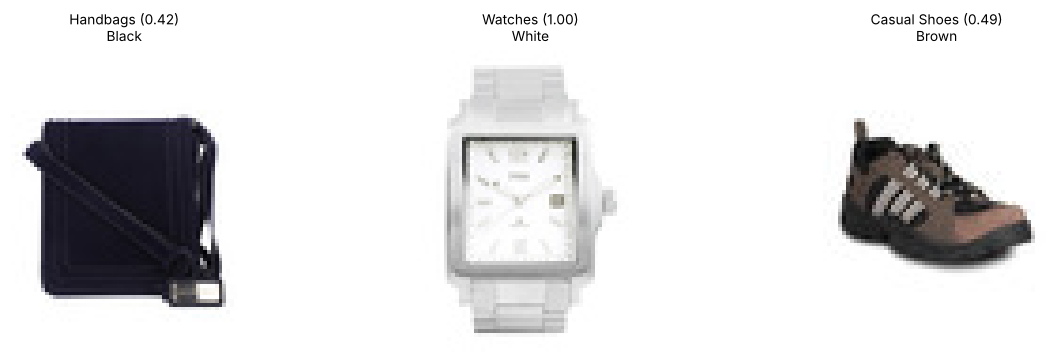

[
  {
    "predicted_type": "Handbags",
    "type_confidence": 0.425,
    "predicted_colour": "Black",
    "description": "Black leather handbag with silver zipper strap.",
    "similar_products": [
      "Baggit Women Volume Jhuti Purple Wallet",
      "Hidekraft Men Black Wallet",
      "United Colors of Benetton Men Solid Black Wallets"
    ],
    "seller_label": "Handbags",
    "needs_review": false,
    "true_title": "French Connection Women Purple Sling Bag"
  },
  {
    "predicted_type": "Watches",
    "type_confidence": 0.998,
    "predicted_colour": "White",
    "description": "White Square Watch.",
    "similar_products": [
      "Fastrack Women Silver Dial Watch",
      "CASIO ENTICER Women Steel-Toned Analogue Watch A446 ",
      "Fastrack Men Black Dial Watch"
    ],
    "seller_label": "Watches",
    "needs_review": false,
    "true_title": "Maxima Men Steel Watch"
  },
  {
    "predicted_type": "Casual Shoes",
    "type_confidence": 0.486,
    "predicted_colour": "Brown"

In [ ]:
def onboard_product(image, seller_label=None, k_similar=3):
    # Create a structured listing for a new product photo.
    emb = clip_image_embed([image])[0]
    p_type = (clip_model.logit_scale.exp().item() * emb @ TYPE_EMB.T).softmax(0)
    t_idx = int(p_type.argmax())
    colour = normalise_colour(ask(image, f"What is the main colour of this product? Choose one of: {options}. "
                                         f"Answer with the colour only.", 6))                       # VLM, constrained (Section 6.8)
    similar = (IMG @ emb).topk(k_similar).indices.tolist()                                         # nearest catalogue products
    description = ask(image, GROUNDED_PROMPT.format(colour=colour.lower(), kind=nice(TOP_TYPES[t_idx])), 50, repetition_penalty=1.15)
    listing = {"predicted_type": TOP_TYPES[t_idx], "type_confidence": round(float(p_type[t_idx]), 3),
               "predicted_colour": colour, "description": description,
               "similar_products": [products["productDisplayName"][j] for j in similar]}
    if seller_label is not None and seller_label in TOP_TYPES:
        agree = float(p_type[TOP_TYPES.index(seller_label)])
        listing["seller_label"] = seller_label
        listing["needs_review"] = bool(agree < 0.05)                 # flag strong disagreement with the seller's label
    return listing

unseen = catalog[~catalog["id"].isin(products["id"]) & catalog["articleType"].isin(TOP_TYPES)].sample(3, random_state=7)
listings = []
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, (_, row) in zip(axes, unseen.iterrows()):
    image = Image.open(io.BytesIO(row["image"]["bytes"])).convert("RGB")
    listing = onboard_product(image, seller_label=row["articleType"])
    listing["true_title"] = row["productDisplayName"]
    listings.append(listing)
    ax.imshow(image); ax.axis("off"); ax.set_title(f"{listing['predicted_type']} ({listing['type_confidence']:.2f})\n{listing['predicted_colour']}", fontsize=9)
save_fig("06g_onboarding_examples")
print(json.dumps(listings, indent=2))
with open(OUTPUT_DIR / "onboarded_listings.json", "w") as f:
    json.dump(listings, f, indent=2)

## 7. Challenges of VLMs — what this notebook measured

| Challenge (literature) | Evidence in this notebook |
|---|---|
| **Compositionality / "bag-of-words" behaviour** (ARO, Winoground) | Section 3.4: an order-insensitive text encoder is stuck at chance on order and attribute-binding tests; word order plus attention fixes it |
| **Hallucination / language prior** (POPE, CHAIR) | Section 4: a "blind" decoder answers fluently at chance accuracy. Section 5.6: the POPE-style probe. Section 6.8: invented details in free descriptions, reduced by grounding |
| **Resolution vs compute** (FastVLM) | Section 2.3: encoder latency grows faster than quadratically in resolution. Section 5.2: tiling multiplies image tokens and time-to-first-token. Section 5.4: the effect on OCR |
| **Prompt sensitivity** | Section 6.2: zero-shot accuracy changes substantially across prompt formats. Section 6.8: constrained vs open questions |
| **Domain shift and label ambiguity** | Section 6.2: the hardest product types are fine-grained siblings (casual vs sports shoes), which also challenge humans |
| **Evaluation difficulty** | Free-form answers need normalisation (Sections 5.4 and 6.8). CLIPScore is reference-free but inherits CLIP's biases (Bordes et al.) |

**Future directions** highlighted by the references:
* more efficient visual encoders and token compression for on-device use (FastVLM, SmolVLM);
* better-curated and synthetic training data;
* grounding and RLHF-style alignment to reduce hallucination;
* skill-level benchmarks;
* extension to video, multi-image reasoning, GUI agents and robotics (vision-language-action models).

## 8. Summary, saved artefacts and references

In [ ]:
summary = pd.DataFrame([
    ["Mini-CLIP (BoW text)", "held-out retrieval / order / binding %",
     " / ".join(f"{v:.1f}" for v in df_clip_eval.loc[("BoW text encoder", "held-out pairs")].values)],
    ["Mini-CLIP (transformer text)", "held-out retrieval / order / binding %",
     " / ".join(f"{v:.1f}" for v in df_clip_eval.loc[("Transformer text encoder", "held-out pairs")].values)],
    ["Mini-LLaVA", "held-out exact-match % (stage 0 → 1 → 2)",
     " → ".join(f"{df_stages.loc[s, 'overall %']:.1f}" for s in df_stages.index[:3])],
    ["SmolVLM", "invoice number / total read correctly % (no tiling)",
     f"{df_ocr[~df_ocr['image splitting']]['number correct'].mean() * 100:.0f} / {df_ocr[~df_ocr['image splitting']]['total correct'].mean() * 100:.0f}"],
    ["SmolVLM", "invoice number / total read correctly % (tiling)",
     f"{df_ocr[df_ocr['image splitting']]['number correct'].mean() * 100:.0f} / {df_ocr[df_ocr['image splitting']]['total correct'].mean() * 100:.0f}"],
    ["SmolVLM", "chart QA % | POPE accuracy %", f"{df_chart['correct'].mean() * 100:.0f} | {pope_summary['accuracy %']:.0f}"],
    ["Use case: CLIP", "zero-shot type accuracy % (raw label → prompt ensemble)",
     f"{df_prompts.iloc[0, 0]:.1f} → {df_prompts.iloc[-1, 0]:.1f}"],
    ["Use case: CLIP + linear probe", "accuracy % with all labels", f"{df_probe.iloc[-1, 1]:.1f}"],
    ["Use case: CLIP", "colour tagging accuracy %", f"{colour_acc:.1f}"],
    ["Use case: CLIP", "title search Recall@10 % | type-precision@5 %", f"{search_metrics['Recall@10 %']:.1f} | {search_metrics['type-precision@5 %']:.1f}"],
    ["Use case: CLIP", "recommendations: same type in top-5 %", f"{rec_type_p5:.1f}"],
    ["Use case: CLIP", "mislabel detection AUROC | precision@k %", f"{auroc:.3f} | {precision_at_k:.1f}"],
    ["Use case: SmolVLM", "colour accuracy % (open → constrained)",
     f"{attr_summary.iloc[0]:.1f} → {attr_summary.iloc[1]:.1f}"],
    ["Use case: SmolVLM", "descriptions with the correct main colour % (free → grounded)",
     f"{desc_summary.loc['main colour stated correctly %', 'free prompt']:.0f} → {desc_summary.loc['main colour stated correctly %', 'grounded prompt']:.0f}"],
    ["Use case: SmolVLM", "generic boilerplate descriptions % (free → grounded)",
     f"{desc_summary.loc['generic store boilerplate %', 'free prompt']:.0f} → {desc_summary.loc['generic store boilerplate %', 'grounded prompt']:.0f}"],
], columns=["Model / component", "Metric", "Result"])
display(summary)

summary.to_csv(OUTPUT_DIR / "summary.csv", index=False)
df_clip_eval.to_csv(OUTPUT_DIR / "mini_clip_evaluation.csv")
df_stages.to_csv(OUTPUT_DIR / "mini_llava_stages.csv")
df_prompts.to_csv(OUTPUT_DIR / "zero_shot_prompting.csv")
df_probe.to_csv(OUTPUT_DIR / "few_shot_probe.csv", index=False)
df_attr.to_csv(OUTPUT_DIR / "vlm_attribute_extraction.csv", index=False)
df_desc.to_csv(OUTPUT_DIR / "vlm_descriptions.csv", index=False)
torch.save({"image_encoder": tf_img.state_dict(), "text_encoder": tf_txt.state_dict()}, OUTPUT_DIR / "mini_clip.pt")
torch.save(llava.state_dict(), OUTPUT_DIR / "mini_llava.pt")
print("Saved files:")
for f in sorted(OUTPUT_DIR.iterdir()):
    print(f"  {f.name:<38} {f.stat().st_size / 1024:8.1f} KB")

,Model / component,Metric,Result
0,Mini-CLIP (BoW text),held-out retrieval / order / binding %,34.3 / 50.0 / 50.0
1,Mini-CLIP (transformer text),held-out retrieval / order / binding %,98.5 / 100.0 / 100.0
2,Mini-LLaVA,held-out exact-match % (stage 0 → 1 → 2),17.8 → 47.3 → 99.7
3,SmolVLM,invoice number / total read correctly % (no ti...,40 / 100
4,SmolVLM,invoice number / total read correctly % (tiling),100 / 100
5,SmolVLM,chart QA % | POPE accuracy %,100 | 94
6,Use case: CLIP,zero-shot type accuracy % (raw label → prompt ...,71.6 → 79.9
7,Use case: CLIP + linear probe,accuracy % with all labels,87.0
8,Use case: CLIP,colour tagging accuracy %,57.3
9,Use case: CLIP,title search Recall@10 % | type-precision@5 %,49.0 | 82.1


Saved files:
  02a_patch_embedding.png                   518.3 KB
  02b_resolution_vs_latency.png              63.3 KB
  03a_scene_dataset.png                      90.5 KB
  03b_mini_clip_training.png                 47.1 KB
  03c_similarity_matrices.png               178.9 KB
  04_mini_llava_outputs.png                  83.2 KB
  05a_clip_zero_shot.png                    306.9 KB
  05b_vlm_sample_images.png                 890.5 KB
  05c_invoice_example.png                    57.8 KB
  05d_chart_example.png                      15.2 KB
  06a_catalog_overview.png                  159.6 KB
  06b_zero_shot_per_class.png               145.0 KB
  06c_few_shot_probe.png                     49.0 KB
  06d_text_search.png                       389.6 KB
  06e_similar_items.png                     348.6 KB
  06f_label_audit.png                       297.6 KB
  06g_onboarding_examples.png                35.5 KB
  few_shot_probe.csv                          0.1 KB
  mini_clip.pt                   

### Key takeaways

1. **A VLM turns pixels into tokens** (patch embedding = strided convolution) and aligns them with language, either in a **shared embedding space** (contrastive: CLIP) or by **feeding visual tokens to an LLM** (generative: LLaVA, SmolVLM).
2. **Contrastive learning** gives powerful zero-shot recognition and retrieval. Its text encoder must respect word order, otherwise it behaves like a **bag of words** and fails compositional tests.
3. **The LLaVA recipe works in miniature:**
    * the language model alone only knows the prior (it hallucinates);
    * aligning just the projector grounds it;
    * instruction tuning makes it accurate, even on unseen combinations.
4. **Visual tokens are the main cost:** they grow quadratically with resolution. Token compression (pixel shuffle) and efficient encoders (FastVLM) are central to practical VLMs, while text-rich images still benefit from higher resolution.
5. **Real-world value:** on a real fashion catalogue, a single CLIP index delivers zero-shot categorisation, colour tagging, semantic search, recommendations and label auditing. A small generative VLM adds descriptions and question answering, and **grounded prompting** reduces hallucinations.

### References
1. Hugging Face, *Vision Language Models Explained* (2024). https://huggingface.co/blog/vlms
2. F. Bordes et al., *An Introduction to Vision-Language Modeling* (2024). arXiv:2405.17247
3. Z. Li et al., *Vision-Language-Models-Overview* (survey repository). https://github.com/zli12321/Vision-Language-Models-Overview
4. BentoML, *Multimodal AI: A Guide to Open-Source Vision Language Models*. https://www.bentoml.com/blog/multimodal-ai-a-guide-to-open-source-vision-language-models
5. Apple Machine Learning Research, *FastVLM: Efficient Vision Encoding for Vision Language Models* (CVPR 2025). https://machinelearning.apple.com/research/fast-vision-language-models
6. Encord, *Guide to Vision-Language Models (VLMs)*. https://encord.com/blog/vision-language-models-guide/
7. A. Radford et al., *Learning Transferable Visual Models From Natural Language Supervision (CLIP)*, ICML 2021. arXiv:2103.00020
8. X. Zhai et al., *Sigmoid Loss for Language Image Pre-Training (SigLIP)*, ICCV 2023. arXiv:2303.15343
9. H. Liu et al., *Visual Instruction Tuning (LLaVA)*, NeurIPS 2023. arXiv:2304.08485
10. J. Li et al., *BLIP-2*, ICML 2023. arXiv:2301.12597; J.-B. Alayrac et al., *Flamingo*, NeurIPS 2022. arXiv:2204.14198
11. A. Marafioti et al., *SmolVLM: Redefining small and efficient multimodal models* (2025). arXiv:2504.05299
12. A. Dosovitskiy et al., *An Image is Worth 16x16 Words (ViT)*, ICLR 2021. arXiv:2010.11929
13. M. Yuksekgonul et al., *When and Why Vision-Language Models Behave like Bags-of-Words (ARO)*, ICLR 2023. arXiv:2210.01936
14. Y. Li et al., *Evaluating Object Hallucination in Large Vision-Language Models (POPE)*, EMNLP 2023. arXiv:2305.10355
15. J. Hessel et al., *CLIPScore: A Reference-free Evaluation Metric for Image Captioning*, EMNLP 2021. arXiv:2104.08718
16. P. Aggarwal, *Fashion Product Images Dataset* (Kaggle), Hugging Face mirror `ashraq/fashion-product-images-small`.